# Early dropout sur CIFAR-10
### Étude expérimentale de *Dropout Reduces Underfitting* · MLP, CNN et ResNet compact

## 1. Introduction et questions de recherche

Le **dropout** masque aléatoirement des activations pendant l’apprentissage. Un neurone disponible à une mise à jour peut ainsi manquer à la suivante. À l’inférence, toutes les activations sont disponibles. On l’utilise souvent pour limiter le **surapprentissage**, lorsque le réseau continue de mieux ajuster ses exemples d’apprentissage sans mieux prédire des exemples nouveaux.

Le **sous-apprentissage** désigne une situation où le réseau pourrait encore mieux ajuster les données d’apprentissage. La section 2 précise le critère expérimental adopté par les auteurs pour identifier les configurations concernées.

Liu et al. posent une question surprenante. Le bruit introduit par ces masques pourrait-il, au début de l’entraînement, aider le réseau à **mieux ajuster les données d’apprentissage elles-mêmes** ? Sur certaines configurations ImageNet, les auteurs obtiennent une perte finale plus basse après avoir coupé les masques en cours d’entraînement. Ils proposent aussi une explication en termes de direction des gradients. Nous examinons ces deux observations à l’échelle de CIFAR-10.

1. **L'early dropout marche-t-il à notre échelle, et sur quels modèles ?**
2. **Existe-t-il une durée de dropout optimale selon le type de modèle ?** Que veut dire « early » : les 10 % premières époques ? 30 % ? 50 % ?

Nous appliquons le dropout aux activations du MLP et du CNN. Sur le ResNet, nous étudions la **stochastic depth** (*profondeur stochastique*) : pendant l’apprentissage, un masque peut annuler la contribution d’une branche résiduelle entière pour une image. Le chemin de raccourci continue alors de transmettre l’information. L’article étudie également ces deux mécanismes. Dans les résultats, le nom du modèle et celui du mécanisme figurent ensemble.

**Source.** Zhuang Liu, Zhiqiu Xu, Joseph Jin, Zhiqiang Shen et Trevor Darrell, ICML 2023. [Article et annexes](https://proceedings.mlr.press/v202/liu23aq/liu23aq.pdf) · [Code des auteurs](https://github.com/facebookresearch/dropout)

**Plan de lecture.** 1. Introduction et questions · 2. Critères de réussite · 3. Dispositif CIFAR-10 · 4. Pilote du taux · 5. Régime et rôle de l’augmentation · 6. Expérience principale · 7. Diagnostic des gradients · 8. Test, discussion et conclusion.

## 2. Comment reconnaître un succès ?

| Question expérimentale | Comparaison prévue | Lecture de la différence |
|---|---|---|
| Sommes-nous dans le régime visé ? | Masquage permanent moins absence de masque, sur l’accuracy de validation | Une différence négative indique que la régularisation permanente pénalise la généralisation. C’est le critère opérationnel de la section 4 de l’article. |
| L’early dropout améliore-t-il l’ajustement ? | Masquage pendant les premiers 30 % moins absence de masque, sur la perte train propre à la dernière époque | Une différence négative favorise la stratégie précoce. C’est le contraste principal, évalué pour chacun des trois modèles. |
| Le gain se transpose-t-il à de nouvelles images ? | Mêmes stratégies, sur l’accuracy de validation puis de test | Une différence positive en points de pourcentage favorise la stratégie précoce. |
| La durée ou le moment changent-ils l’effet ? | Comparaisons entre 10 %, 30 % et 50 %, puis entre les premiers et les derniers 30 % | La première série compare les durées. La seconde maintient la durée et change le moment. |

La **perte** utilisée ici est l’entropie croisée, soit la moyenne de −log de la probabilité attribuée à la vraie classe. Une prédiction correcte mais hésitante coûte davantage qu’une prédiction correcte et confiante. L’**accuracy** compte la proportion de classes correctement prédites. Passer de 70 à 71 % représente +1 point. Ces métriques peuvent évoluer différemment.

Une **graine** fixe les tirages aléatoires d’un entraînement. À graine identique, deux stratégies partent des mêmes poids, voient les mêmes exemples dans le même ordre et, si l’augmentation est activée, reçoivent les mêmes transformations. Nous calculons d’abord la différence *au sein* de chaque paire, puis la moyenne de ces différences. Un **intervalle de confiance à 95 %** de Student décrit l’incertitude liée aux graines pour le découpage de données choisi. Avec trois ou cinq paires, un seul point peut peser lourd. Les figures montrent donc les différences individuelles.

**Parcours.** Nous choisissons le taux puis l’augmentation sur un CNN pilote, puis cherchons un régime par architecture avec trois graines. Cinq graines distinctes servent à vérifier ce régime et à répondre aux deux questions. Les gradients et le test interviennent après la comparaison principale.

### Mode d’emploi

- `MODE = "lecture"` reconstruit tableaux, figures et interprétations à partir des entraînements disponibles dans le dossier de résultats. Une première lecture permet aussi d’examiner le protocole sans télécharger CIFAR-10.
- `MODE = "etude"` exécute la campagne complète. Un entraînement achevé peut être relu après un redémarrage. Le pilote compte 15 runs, le balayage 162, la vérification du régime 30, le pilote d’augmentation 15 runs supplémentaires et les fenêtres précoces et tardive 60. Cela représente 282 entraînements au total.
- `MODE = "rapide"` parcourt la même chaîne sur un sous-ensemble, avec une grille réduite et les mêmes nombres de graines. Ses résultats servent à vérifier l’exécution. Ils sont stockés à part.
- Le test officiel se déclenche avec `RUN_TEST = True` après fixation des choix. Le nouveau dossier de résultats isole ce protocole de celui où le MLP et le CNN utilisaient un masque juste avant le classifieur. L’équipe a déjà consulté le test CIFAR-10 lors de son étude antérieure.

**Suivi en direct.** `VERBOSE = True` est activé par défaut. En mode `"rapide"` ou `"etude"`, la première barre situe l’entraînement dans sa phase et indique le modèle, la stratégie et la graine. La seconde suit les époques et affiche la perte train propre, l’accuracy de validation et le taux de masquage. Le compteur de phase distingue les runs calculés de ceux relus. Le mode `"lecture"` affiche le bilan des sauvegardes disponibles.

**Environnement.** Python, PyTorch et torchvision pour les réseaux et les données, NumPy pour les tirages, pandas pour les tableaux, SciPy pour les intervalles statistiques et Matplotlib pour les figures. Le dossier `DATA_ROOT` peut pointer vers une copie existante de CIFAR-10.

**Retrouver un entraînement.** Chaque phase sauvegarde une paire JSON/PT par run. Le nom indique modèle, stratégie, taux, largeur, budget et graine. Les index CSV associent aussi les anciens noms à empreinte seule à leur configuration. Consulter `pilote/index_pilote.csv`, `exploration/index_exploration.csv` ou les index `ablation/index_with_aug.csv` et `ablation/index_without_aug.csv` pour les phases correspondantes. Dans `validation/`, `index_controls.csv` recense les témoins et `index_windows.csv` les fenêtres précoces et tardives. Une fois les deux séries complètes, `index_main.csv` regroupe leurs 90 runs.

In [1]:
# Dépendances (à décommenter si besoin) :
# %pip install torch torchvision numpy pandas scipy matplotlib tqdm

import os
# Requis par les algorithmes déterministes de PyTorch sur GPU (à définir avant toute initialisation CUDA).
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')

import math, random, json, hashlib, tempfile
from itertools import combinations, product
from dataclasses import dataclass, asdict, replace
from pathlib import Path

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from torch import nn
import torch.nn.functional as F
from tqdm.auto import tqdm
from IPython.display import display

pd.set_option('display.max_rows', 30)
pd.set_option('display.width', 200)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch', torch.__version__, '| device :', device)

# Reproductibilité : on demande des algorithmes déterministes (simple avertissement si impossible).
torch.use_deterministic_algorithms(True, warn_only=True)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
from torchvision import datasets
from torchvision.ops import StochasticDepth
from IPython.display import Markdown

MODE = "etude"              # "lecture", "rapide" ou "etude"
VERBOSE = True               # Afficher la progression des phases, des époques et du test.
RUN_TEST = True
DATA_ROOT = Path("./data")
assert MODE in {"lecture", "rapide", "etude"}
RUN_TRAINING = MODE != "lecture"
# Pour relire les résultats de démonstration, mettre READ_QUICK_RESULTS à True.
READ_QUICK_RESULTS = False
QUICK_MODE = MODE == "rapide" or (MODE == "lecture" and READ_QUICK_RESULTS)
OUT = Path("resultats_cifar10_v3") / ("rapide" if QUICK_MODE else "etude")
OUT.mkdir(parents=True, exist_ok=True)
print("Mode", MODE, "· résultats", OUT.resolve())

PyTorch 2.15.0+cu132 | device : cuda
Mode etude · résultats /home/nibir/projects/projet dl final/resultats_cifar10_v3/etude


## 3. Dispositif CIFAR-10 · données, modèles et budget commun

**CIFAR-10** contient des images couleur de 32 × 32 pixels, réparties en dix classes. Sur les 50 000 images d’apprentissage officielles, 45 000 servent à ajuster les poids et 5 000 à prendre les décisions expérimentales. Un sous-ensemble fixe de 5 000 images des 45 000 permet de mesurer l’ajustement sans évaluer tout le train à chaque époque. Les 10 000 images de test sont évaluées à la fin.

Une **époque** est un passage sur les données d’apprentissage. Un **mini-lot** est le groupe d’images utilisé pour une mise à jour des poids. Une époque complète contient ici 352 mises à jour au batch de 128. Une **largeur** ×0,5 divise approximativement par deux le nombre d’unités ou de canaux de chaque couche. La grille des largeurs et des budgets explore ensemble les effets de capacité et de temps d’optimisation.

In [2]:
@dataclass(frozen=True)
class Config:
    '''Hyperparamètres COMMUNS à toutes les architectures et à toutes les stratégies.'''
    # --- Optimisation ---
    batch_size: int = 128
    lr: float = 1e-3
    lr_min_ratio: float = 0.01      # plancher de la décroissance cosinus (1 % du lr max)
    warmup_epochs: float = 1.0      # montée linéaire du lr pendant 1 époque
    weight_decay: float = 0.0       # AdamW sans weight decay : décroissance des poids désactivée
    dropout_p: float = 0.10         # taux de dropout, identique pour standard, early et late
    # --- Transformations des exemples de train ---
    aug_crop_pad: int = 4           # crop aléatoire après padding de 4 pixels (0 = désactivé)
    aug_flip: bool = True           # flip horizontal
    aug_cutout: int = 8             # carré effacé de 8x8 pixels (0 = désactivé)
    aug_mixup_alpha: float = 0.4    # mixup (0 = désactivé)
    # --- Données ---
    val_size: int = 5000
    train_subset: int = 0           # 0 = tout le train (45 000) ; >0 : sous-échantillon (mode rapide)
    train_eval_size: int = 5000     # images du train utilisées pour mesurer la perte d'entraînement
    split_seed: int = 2026
    # --- Les deux variables du régime : fixées par le balayage (étape 1) ---
    width_mult: float = 1.0         # facteur appliqué à la largeur de chaque couche
    epochs: int = 30                # budget d'entraînement
    # --- Diagnostics de gradient (section 4) ---
    grad_batches: int = 32          # nombre de mini-lots de sondage
    grad_batch_size: int = 128
    grad_ref_size: int = 4096       # images servant à estimer le gradient du jeu complet
    grad_mask_seed: int = 1234



PILOT_SEEDS = (31, 32, 33, 34, 35)
SWEEP_SEEDS = (0, 1, 2)
MAIN_SEEDS = (42, 123, 456, 789, 1011)
ARCHITECTURES = ("mlp", "cnn", "resnet")
METHOD = {"mlp": "Dropout", "cnn": "Dropout", "resnet": "Stochastic depth"}
WIDTH_GRID = (0.5, 1.0, 2.0)
EPOCH_GRID = (10, 20, 40)
EARLY_FRACTIONS, LATE_FRACTION = (0.10, 0.30, 0.50), 0.30
DIAG_EPOCHS = (0, 1, 2, 3, 5, 8, 12, 20, 30, 40)
BASE = Config()
if QUICK_MODE:
    BASE = replace(BASE, train_subset=1024, val_size=256, train_eval_size=256,
                   grad_batches=3, grad_batch_size=32, grad_ref_size=128)
    WIDTH_GRID, EPOCH_GRID = (0.5,), (10,)
    DIAG_EPOCHS = (0, 1, 3, 10)

def without_augmentation(cfg):
    return replace(cfg, aug_crop_pad=0, aug_flip=False, aug_cutout=0, aug_mixup_alpha=0)

### 3.1. Qu’apprend-on en transformant une image ?

L’**augmentation de données** crée, au moment de former le mini-lot, de nouvelles versions des exemples d’apprentissage. Sur CIFAR-10, un petit déplacement ou un reflet horizontal préserve souvent la classe. Le **cutout** occulte une zone et oblige le réseau à exploiter d’autres indices. Le **mixup** interpole deux images et attribue à leurs classes les mêmes poids que dans le mélange. Ces choix rapprochent notre entraînement de l’esprit de la recette ImageNet des auteurs. Nous vérifierons expérimentalement si cette recette contribue au régime observé.

| Transformation | Réglage | Conséquence |
|---|---|---|
| Recadrage aléatoire | Bordure de 4 pixels puis fenêtre de 32 × 32 | Déplacement apparent de l’objet |
| Reflet horizontal | Probabilité 0,5 | Changement d’orientation |
| Cutout | Carré de côté 8, tronqué s’il touche un bord | Zone masquée par la moyenne du canal |
| Mixup | Coefficient λ tiré selon une loi Beta(0,4 ; 0,4) | Cible pondérée entre deux classes |

La **normalisation** centre et réduit séparément les trois canaux couleur. Elle s’applique aussi aux images propres et reste active dans l’ablation. Pendant l’apprentissage, la perte avec mixup est une somme pondérée de deux entropies croisées. Pour comparer l’ajustement entre stratégies, nous évaluons les images originales avec leur vraie classe et tous les masques désactivés.

In [3]:
def load_images(train):
    """torchvision charge CIFAR-10. Le stockage uint8 limite la mémoire utilisée."""
    data = datasets.CIFAR10(DATA_ROOT, train=train, download=True)
    x = torch.from_numpy(data.data).permute(0, 3, 1, 2).contiguous()
    return x, torch.tensor(data.targets, dtype=torch.long)

as_idx = lambda a: torch.from_numpy(np.ascontiguousarray(a))
if RUN_TRAINING:
    x, y = load_images(train=True)
    ids = np.random.default_rng(BASE.split_seed).permutation(len(x))
    va, tr = ids[:BASE.val_size], ids[BASE.val_size:]
    if BASE.train_subset:
        tr = tr[:BASE.train_subset]
    ev = np.random.default_rng(BASE.split_seed + 1).choice(
        tr, size=min(BASE.train_eval_size, len(tr)), replace=False)
    Xtr, ytr = x[as_idx(tr)].to(device), y[as_idx(tr)].to(device)
    Xva, yva = x[as_idx(va)].to(device), y[as_idx(va)].to(device)
    Xev, yev = x[as_idx(ev)].to(device), y[as_idx(ev)].to(device)
    del x, y
    print(f"Train {len(tr):,} · validation {len(va):,} · train propre {len(ev):,}")
# Normalisation par canal (moyennes et écarts-types de CIFAR-10, reprises par la plupart des implémentations de référence)
MEAN = torch.tensor((0.4914, 0.4822, 0.4465), device=device).view(1, 3, 1, 1)
STD = torch.tensor((0.2470, 0.2435, 0.2616), device=device).view(1, 3, 1, 1)

def prep(x_u8):
    '''uint8 -> float32 normalisé (images PROPRES, utilisées pour toutes les mesures).'''
    return (x_u8.float().div(255) - MEAN) / STD

def augment(x_u8, gen, cfg):
    '''Augmentation sur le périphérique : crop aléatoire + flip + normalisation + cutout.
    Tout l'aléa vient du générateur `gen` (dédié aux données, indépendant du dropout).'''
    B = x_u8.shape[0]
    x = x_u8.float().div(255)
    pad = cfg.aug_crop_pad
    if pad > 0:
        # Crop aléatoire : on ajoute un cadre de zéros, puis on découpe 32x32 à une position aléatoire par image.
        xp = F.pad(x, (pad, pad, pad, pad))
        oy = torch.randint(0, 2 * pad + 1, (B,), device=device, generator=gen)
        ox = torch.randint(0, 2 * pad + 1, (B,), device=device, generator=gen)
        ar = torch.arange(32, device=device)
        b_idx = torch.arange(B, device=device)[:, None, None, None]
        c_idx = torch.arange(3, device=device)[None, :, None, None]
        rows = (oy[:, None] + ar)[:, None, :, None]
        cols = (ox[:, None] + ar)[:, None, None, :]
        x = xp[b_idx, c_idx, rows, cols]
    if cfg.aug_flip:
        flip = torch.rand(B, device=device, generator=gen) < 0.5      # une image sur deux est retournée
        x = torch.where(flip[:, None, None, None], x.flip(3), x)
    x = (x - MEAN) / STD
    if cfg.aug_cutout > 0:
        # Cutout : un carré de côté s est mis à 0 à une position aléatoire.
        s = cfg.aug_cutout
        cy = torch.randint(0, 32, (B,), device=device, generator=gen)
        cx = torch.randint(0, 32, (B,), device=device, generator=gen)
        ar = torch.arange(32, device=device)
        in_y = (ar[None] >= (cy[:, None] - s // 2)) & (ar[None] < (cy[:, None] + s - s // 2))
        in_x = (ar[None] >= (cx[:, None] - s // 2)) & (ar[None] < (cx[:, None] + s - s // 2))
        x = x.masked_fill((in_y[:, :, None] & in_x[:, None, :])[:, None], 0.0)
    return x

Train 45,000 · validation 5,000 · train propre 5,000


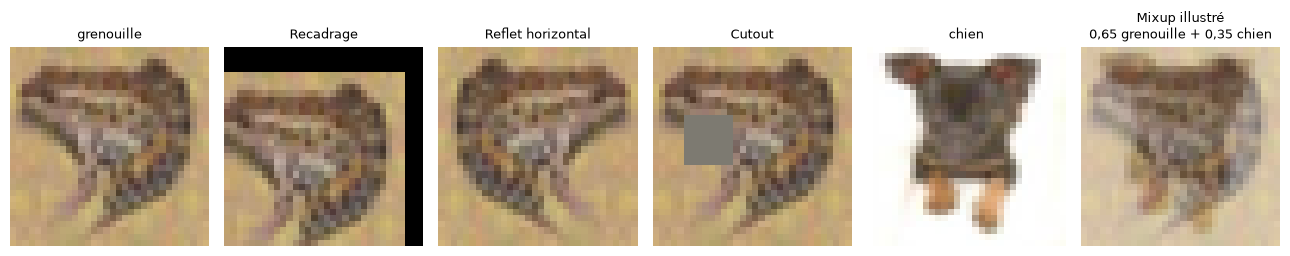

In [4]:
CLASS_NAMES = ("avion", "voiture", "oiseau", "chat", "cerf", "chien", "grenouille", "cheval", "bateau", "camion")

def show_augmentation_examples():
    # Les mêmes images servent aux panneaux, chaque transformation est isolée.
    gen = torch.Generator(device=device).manual_seed(2026)
    i = (ytr != ytr[0]).nonzero()[0, 0].item()
    x = Xtr[:1]
    no_aug_config = without_augmentation(BASE)
    first_label, second_label = CLASS_NAMES[ytr[0].item()], CLASS_NAMES[ytr[i].item()]
    a, b = prep(x), prep(Xtr[i:i+1])
    panels = [
        (first_label, a), ("Recadrage", augment(x, gen, replace(no_aug_config, aug_crop_pad=4))),
        ("Reflet horizontal", a.flip(3)), ("Cutout", augment(x, gen, replace(no_aug_config, aug_cutout=8))),
        (second_label, b), (f"Mixup illustré\n0,65 {first_label} + 0,35 {second_label}", 0.65*a + 0.35*b)]
    fig, axes = plt.subplots(1, 6, figsize=(13, 2.8))
    for ax, (title, image) in zip(axes, panels):
        rgb = (image * STD + MEAN).clamp(0, 1)[0].permute(1, 2, 0).cpu()
        ax.imshow(rgb)
        ax.set_title(title, fontsize=9)
        ax.axis("off")
    fig.tight_layout()
    fig.savefig(OUT / "augmentations.png", dpi=150)
    plt.show()

if RUN_TRAINING:
    show_augmentation_examples()
elif (OUT / "augmentations.png").exists():
    from IPython.display import Image
    display(Image(filename=str(OUT / "augmentations.png")))

### 3.2. Trois architectures, deux types de masques

Une **architecture** décrit les couches du réseau et la façon dont elles sont reliées. Les trois modèles produisent dix **logits**, scores que l’entropie croisée transforme en probabilités pour calculer la perte.

| Modèle | Comment l’image devient une prédiction | Où intervient le masque ? |
|---|---|---|
| MLP · perceptron multicouche | L’image est aplatie puis traitée par trois couches denses. Chaque unité combine toutes les entrées de la couche précédente. | Après les ReLU des deux premières couches cachées. Chaque vecteur masqué alimente la couche dense suivante. |
| CNN · réseau convolutif | Des filtres appris parcourent l’image. Un max-pooling conserve les maxima locaux et réduit la résolution. Une moyenne spatiale résume les cartes finales. | Après le max-pooling des deux premiers blocs. Le dropout masque des activations individuelles de la carte, avant la convolution suivante. |
| ResNet compact · réseau résiduel | Trois blocs apprennent des corrections successives. Chaque bloc additionne une branche apprise et un raccourci qui transmet l’entrée, avec une projection si la forme change. | Un masque scalaire par image et par bloc annule ou conserve la branche apprise. Le classifieur reçoit directement les caractéristiques finales. |

**Stochastic depth.** Dans un bloc, si la branche vaut $F(x)$ et le raccourci $S(x)$, la somme en entraînement est $S(x) + m F(x)/(1-p)$, où le masque de Bernoulli vaut 1 avec probabilité $1-p$. Le facteur de remise à l’échelle conserve l’espérance de la contribution de la branche à poids et entrée fixés. En évaluation, on additionne directement les deux branches. Nous utilisons un taux uniforme sur les trois blocs et un tirage indépendant par image (mode `row`). Un même chiffre $p$ désigne donc deux interventions différentes selon l’architecture.

**Choix de normalisation.** Les trois modèles fonctionnent sans BatchNorm, la couche qui normalise les activations à partir des statistiques du mini-lot. Le ResNet est une variante compacte pour cette expérience. Son régime et ses scores doivent être mesurés avec cette définition. La fonction **ReLU** appliquée aux activations conserve les valeurs positives et annule les valeurs négatives. [Opérateur stochastic depth de torchvision](https://docs.pytorch.org/vision/stable/generated/torchvision.ops.stochastic_depth.html)

In [5]:
def scaled(n, mult):
    '''Largeur n multipliée par mult, au moins 4.'''
    return max(4, int(round(n * mult)))

class GlobalAvgPool(nn.Module):
    '''Moyenne sur les dimensions spatiales : (B, C, H, W) -> (B, C).'''
    def forward(self, x):
        return x.mean(dim=(2, 3))

class ResidualBlock(nn.Module):
    """Le raccourci reste accessible à chaque image, quel que soit le masque."""
    def __init__(self, c_in, c_out, stride, p):
        super().__init__()
        self.conv1 = nn.Conv2d(c_in, c_out, 3, stride, padding=1)
        self.conv2 = nn.Conv2d(c_out, c_out, 3, padding=1)
        self.mask = StochasticDepth(p, mode="row")
        self.shortcut = nn.Identity()
        if stride != 1 or c_in != c_out:
            self.shortcut = nn.Conv2d(c_in, c_out, 1, stride)

    def forward(self, x):
        branch = self.conv2(F.relu(self.conv1(x)))
        return F.relu(self.shortcut(x) + self.mask(branch))

def build_model(arch, cfg):
    '''Construit le modèle `arch` avec la largeur cfg.width_mult et le dropout cfg.dropout_p.'''
    m, p = cfg.width_mult, cfg.dropout_p
    if arch == 'mlp':
        h1, h2, h3 = (scaled(n, m) for n in (256, 128, 64))
        feats = nn.Sequential(
            nn.Flatten(), nn.Linear(3 * 32 * 32, h1), nn.ReLU(), nn.Dropout(p),
            nn.Linear(h1, h2), nn.ReLU(), nn.Dropout(p),
            nn.Linear(h2, h3), nn.ReLU())
        return nn.Sequential(feats, nn.Linear(h3, 10))
    if arch == 'cnn':
        c1, c2, c3, fc = (scaled(n, m) for n in (48, 96, 192, 96))
        feats = nn.Sequential(
            nn.Conv2d(3, c1, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Dropout(p),
            nn.Conv2d(c1, c2, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Dropout(p),
            nn.Conv2d(c2, c3, 3, padding=1), nn.ReLU(),
            GlobalAvgPool(), nn.Linear(c3, fc), nn.ReLU())
        return nn.Sequential(feats, nn.Linear(fc, 10))
    if arch == 'resnet':
        c1, c2, c3, fc = (scaled(n, m) for n in (16, 32, 64, 128))
        feats = nn.Sequential(
            nn.Conv2d(3, c1, 3, padding=1), nn.ReLU(),
            ResidualBlock(c1, c1, 1, p),          # (B, c1, 32, 32)
            ResidualBlock(c1, c2, 2, p),          # (B, c2, 16, 16)
            ResidualBlock(c2, c3, 2, p),          # (B, c3, 8, 8)
            GlobalAvgPool(), nn.Linear(c3, fc), nn.ReLU())
        return nn.Sequential(feats, nn.Linear(fc, 10))
    raise ValueError(arch)

def count_params(arch, cfg):
    return sum(p.numel() for p in build_model(arch, cfg).parameters())

def mask_layers(model):
    """Seuls ces modules changent de taux au fil des époques."""
    return [m for m in model.modules() if isinstance(m, (nn.Dropout, StochasticDepth))]

def set_mask_rate(model, p):
    for m in mask_layers(model):
        m.p = p

display(pd.DataFrame([
    {"modèle": arch.upper(), "mécanisme": METHOD[arch], "largeur": w,
     "paramètres entraînables": count_params(arch, replace(BASE, width_mult=w))}
    for arch, w in product(ARCHITECTURES, WIDTH_GRID)]))

,modèle,mécanisme,largeur,paramètres entraînables
0,MLP,Dropout,0.5,404010
1,MLP,Dropout,1.0,828490
2,MLP,Dropout,2.0,1738890
3,CNN,Dropout,0.5,57802
4,CNN,Dropout,1.0,228490
5,CNN,Dropout,2.0,908554
6,RESNET,Stochastic depth,0.5,22218
7,RESNET,Stochastic depth,1.0,86666
8,RESNET,Stochastic depth,2.0,342282


### 3.3. Calendriers de masquage et d’optimisation

Le **taux de masquage** $p$ règle l’intensité lorsque le mécanisme est actif. Sa **durée** est le nombre d’époques actives. Le taux est constant dans la fenêtre puis tombe à zéro. Par exemple, sur dix époques, `early_30` active le masque aux époques 1 à 3 et `late_30` aux époques 8 à 10. Dans la suite, `standard` signifie actif pendant toutes les époques et `none` signifie taux nul.

Le **taux d’apprentissage** règle l’amplitude des mises à jour des poids. Le **scheduler** fait varier ce taux au fil des mises à jour. Ici, il augmente linéairement pendant une époque de **warmup** (montée en régime) puis décroît selon une courbe cosinus. **AdamW** adapte les mises à jour à partir de moyennes des gradients et de leurs carrés. Son paramètre de décroissance des poids (*weight decay*) est fixé à zéro. Les deux calendriers, masquage et taux d’apprentissage, agissent simultanément. Pour un budget de dix époques, la stratégie à 10 % couvre exactement le warmup.

Stratégies : ['none', 'standard', 'early_10', 'early_30', 'early_50', 'late_30']


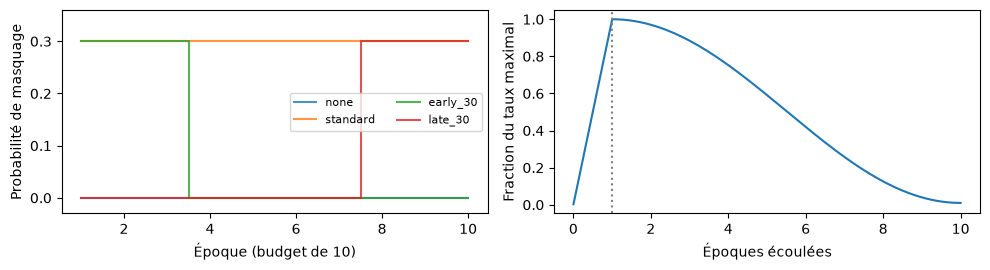

In [6]:
def round_half_up(x):
    return math.floor(x + 0.5)

PRIMARY = 'early_30'                                          # contraste principal : early_30 contre none
EARLY = [f'early_{round(100 * f)}' for f in EARLY_FRACTIONS]  # ['early_10', 'early_30', 'early_50']
LATE = f'late_{round(100 * LATE_FRACTION)}'                   # 'late_30'
STRATEGIES = ['none', 'standard'] + EARLY + [LATE]
assert PRIMARY in EARLY

def n_active_epochs(strategy, total):
    '''Nombre d'époques pendant lesquelles le dropout est actif.'''
    if strategy == 'none':
        return 0
    if strategy == 'standard':
        return total
    pct = int(strategy.split('_')[1])                          # early_30 -> 30 %
    return max(1, min(total, round_half_up(pct / 100 * total)))

def dropout_rate(strategy, epoch, total, p):
    '''Taux de dropout utilisé pendant l'époque `epoch` (numérotée de 1 à total).'''
    n = n_active_epochs(strategy, total)
    if strategy.startswith('late'):
        active = epoch > total - n          # fenêtre à la FIN de l'entraînement
    else:
        active = epoch <= n                 # none (n=0), standard (n=total), early : fenêtre au DÉBUT
    return p if active else 0.0

print('Stratégies :', STRATEGIES)

# Repère visuel indépendant de tout entraînement.
fig, axes = plt.subplots(1, 2, figsize=(10, 2.8))
for strategy in ("none", "standard", "early_30", "late_30"):
    e = np.arange(1, 11)
    axes[0].step(e, [dropout_rate(strategy, t, 10, 0.3) for t in e],
                 where="mid", label=strategy, alpha=0.8)
axes[0].set(xlabel="Époque (budget de 10)", ylabel="Probabilité de masquage", ylim=(-0.03, 0.36))
axes[0].legend(fontsize=8, ncol=2)
def lr_factor(step, total, warmup, floor):
    if step < warmup:
        return (step + 1) / warmup
    t = min(1.0, (step - warmup) / max(1, total - 1 - warmup))
    return floor + (1 - floor) * (1 + math.cos(math.pi * t)) / 2

steps = np.arange(3520)
axes[1].plot((steps+1)/352, [lr_factor(k, 3520, 352, BASE.lr_min_ratio) for k in steps])
axes[1].axvline(1, ls=":", color="gray")
axes[1].set(xlabel="Époques écoulées", ylabel="Fraction du taux maximal")
fig.tight_layout()
plt.show()

### 3.4. Moteur commun et traces conservées

Un **gradient** est le vecteur des dérivées de la perte par rapport aux poids. L’optimiseur utilise le gradient d’un mini-lot pour mettre à jour ces poids. Un **checkpoint** est une sauvegarde des poids ; elle permet d’évaluer le modèle final sans le réentraîner.

La boucle suivante est la même pour toutes les stratégies. L’ordre des exemples, les transformations, le mixup et les masques ont des sources d’aléa distinctes. Cela maintient les paires comparables lorsque l’on retire l’augmentation. À chaque époque, nous enregistrons la perte propre et l’accuracy train/validation, le taux de masquage, le taux d’apprentissage et la distance des poids à leur initialisation. Les sondes de gradient sont limitées au contraste principal ; leur interprétation vient en section 7.

In [7]:
def flat_grad(model, params, idx):
    '''Gradient de la perte (images propres) sur les images idx, aplati en un seul vecteur.'''
    loss = F.cross_entropy(model(prep(Xtr[idx])), ytr[idx])
    return torch.cat([g.reshape(-1) for g in torch.autograd.grad(loss, params)])

def mean_gradient(model, params, idx, chunk=1024):
    '''Gradient moyen sur beaucoup d'images, calculé par morceaux pour économiser la mémoire.'''
    total = 0
    for i in range(0, len(idx), chunk):
        part = idx[i:i + chunk]
        total = total + flat_grad(model, params, part) * len(part)
    return total / len(idx)

def make_probe_split(seed, cfg):
    '''Lots de sondage + images de référence, disjoints. Dépendent de la graine, pas de la stratégie.'''
    n_probe = cfg.grad_batches * cfg.grad_batch_size
    assert n_probe + cfg.grad_ref_size <= len(Xtr), 'jeu de sondage trop grand pour le jeu d’entraînement'
    p = np.random.default_rng(777 + seed).permutation(len(Xtr))
    return as_idx(p[:n_probe]).to(device), as_idx(p[n_probe:n_probe + cfg.grad_ref_size]).to(device)

def gradient_diagnostics(model, probe_idx, ref_idx, epoch, cfg):
    '''Métriques de gradient de l'article (section 3) mesurées sur un checkpoint.

    Deux modes sur les MÊMES poids :
      - eval   : sans masque (gradient du réseau complet) ;
      - masked : mécanisme de masquage actif au taux cfg.dropout_p, quelle que soit la stratégie d'entraînement.
    Retourne une liste de deux dictionnaires (un par mode).'''
    params = list(model.parameters())
    bs = cfg.grad_batch_size
    m = len(probe_idx) // bs
    assert m >= 2, 'il faut au moins 2 lots de sondage'
    was_training = model.training
    modules = mask_layers(model)
    old_rates = [m.p for m in modules]
    model.eval()
    devices = [torch.cuda.current_device()] if device.type == 'cuda' else []
    rows = []
    with torch.random.fork_rng(devices=devices):  # le diagnostic ne perturbe pas l'aléa de l'entraînement
        # Gradient de référence g_hat : réseau complet (sans masque), moyenné sur ref_idx.
        set_mask_rate(model, 0.0)
        g_hat = mean_gradient(model, params, ref_idx)
        g_hat = g_hat / g_hat.norm().clamp_min(1e-12)
        for mode in ('eval', 'masked'):
            for layer in modules:
                layer.train(mode == 'masked')
                layer.p = cfg.dropout_p
            torch.manual_seed(cfg.grad_mask_seed + epoch)  # mêmes masques pour toutes les stratégies
            G = torch.stack([flat_grad(model, params, probe_idx[b * bs:(b + 1) * bs]) for b in range(m)])
            norms = G.norm(dim=1)
            U = G / norms.clamp_min(1e-12)[:, None]       # directions unitaires, matrice m x D
            mean_cos = ((U @ U.T).sum() - m) / (m * (m - 1))   # cosinus moyen entre paires DISTINCTES
            rows.append(dict(epoch=epoch, mode=mode,
                             grad_norm=norms.mean().item(),
                             gdv=(0.5 * (1 - mean_cos)).item(),          # variance de direction
                             gde=(0.5 * (1 - U @ g_hat)).mean().item())) # erreur de direction
    for layer, p in zip(modules, old_rates):
        layer.p = p
    model.train(was_training)
    return rows

In [8]:
def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def flat_params(model):
    return torch.cat([p.detach().reshape(-1) for p in model.parameters()])

@torch.no_grad()
def evaluate(model, X, y, bs=512):
    '''Perte et accuracy (fraction) en mode eval (dropout coupé), sur images propres.'''
    was_training = model.training
    model.eval()
    loss_sum = torch.zeros((), device=device)
    correct = torch.zeros((), device=device)
    for i in range(0, len(X), bs):
        logits = model(prep(X[i:i + bs]))
        yy = y[i:i + bs]
        loss_sum += F.cross_entropy(logits, yy, reduction='sum')
        correct += (logits.argmax(1) == yy).sum()
    model.train(was_training)
    return {'loss': loss_sum.item() / len(X), 'accuracy': correct.item() / len(X)}

def mixup_loss(model, x, y, gen, mix_rng, cfg):
    '''Perte avec mixup : on mélange le lot avec une version permutée de lui-même.'''
    if cfg.aug_mixup_alpha <= 0:
        return F.cross_entropy(model(x), y)
    lam = float(mix_rng.beta(cfg.aug_mixup_alpha, cfg.aug_mixup_alpha))
    j = torch.randperm(len(x), generator=gen, device=device)
    logits = model(lam * x + (1 - lam) * x[j])
    return lam * F.cross_entropy(logits, y) + (1 - lam) * F.cross_entropy(logits, y[j])

In [9]:
def train_model(arch, strategy, seed, cfg, diagnostic):
    """Une graine, une configuration, un calendrier. Renvoie les traces et les poids finaux."""
    seed_everything(seed)
    model = build_model(arch, cfg).to(device)
    initial_weights = flat_params(model).clone()
    opt = torch.optim.AdamW(model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)
    n_steps = math.ceil(len(Xtr) / cfg.batch_size)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda k: lr_factor(
        k, n_steps * cfg.epochs, round(n_steps * cfg.warmup_epochs), cfg.lr_min_ratio))
    order_rng = torch.Generator(device=device).manual_seed(seed + 10_000)
    aug_rng = torch.Generator(device=device).manual_seed(seed + 20_000)
    mix_rng = np.random.default_rng(seed + 30_000)
    history, gradients = [], []
    if diagnostic:
        probe, ref = make_probe_split(seed, cfg)
        gradients.extend(gradient_diagnostics(model, probe, ref, 0, cfg))

    epoch_bar = tqdm(range(1, cfg.epochs + 1), desc=f"  {arch.upper()} · {strategy} · graine {seed}",
                     unit="ép.", leave=False, disable=not VERBOSE)
    for epoch in epoch_bar:
        model.train()
        p = dropout_rate(strategy, epoch, cfg.epochs, cfg.dropout_p)
        set_mask_rate(model, p)
        order = torch.randperm(len(Xtr), device=device, generator=order_rng)
        for idx in order.split(cfg.batch_size):
            x = augment(Xtr[idx], aug_rng, cfg)
            loss = mixup_loss(model, x, ytr[idx], aug_rng, mix_rng, cfg)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            sched.step()
        # Même mesure propre pour toutes les conditions, y compris avec mixup.
        tr = evaluate(model, Xev, yev)
        va = evaluate(model, Xva, yva)
        history.append(dict(epoch=epoch, p=p, lr=opt.param_groups[0]["lr"],
                            train_loss=tr["loss"], train_acc=100*tr["accuracy"],
                            val_loss=va["loss"], val_acc=100*va["accuracy"],
                            distance=(flat_params(model) - initial_weights).norm().item()))
        if VERBOSE:
            print(f"  Époque {epoch}/{cfg.epochs} · perte train {tr['loss']:.3f} · "
                  f"accuracy validation {100*va['accuracy']:.1f} %", flush=True)
            epoch_bar.set_postfix_str(f"époque {epoch}/{cfg.epochs} · perte train {tr['loss']:.3f} · validation {100*va['accuracy']:.1f} % · p {p:.2f}")
        if diagnostic and epoch in DIAG_EPOCHS:
            gradients.extend(gradient_diagnostics(model, probe, ref, epoch, cfg))
    weights = {k: v.detach().cpu() for k, v in model.state_dict().items()}
    return history, gradients, weights

In [10]:
PROTOCOL_VERSION = "cifar10-v4-hidden-dropout-resnet-sd"  # À changer si la définition d'un modèle change.

def load_or_train_run(phase, arch, strategy, seed, cfg, diagnostic=False):
    """Lecture par identité complète. Le JSON est publié après les poids."""
    # Cette clé du format de sauvegarde assure la relecture des entraînements existants.
    run_identity = {"protocole": PROTOCOL_VERSION, "phase": phase, "arch": arch, "strategy": strategy,
                "seed": seed, "cfg": asdict(cfg), "diagnostic": diagnostic,
                "diag_epochs": list(DIAG_EPOCHS) if diagnostic else []}
    key = hashlib.sha256(json.dumps(run_identity, sort_keys=True).encode()).hexdigest()[:24]
    folder = OUT / phase
    # Le préfixe décrit le run ; le suffixe distingue toutes les autres options du protocole.
    stem = (f"{arch}_{strategy}_p{cfg.dropout_p:g}_w{cfg.width_mult:g}_"
            f"e{cfg.epochs}_seed{seed}_{key}")
    path, checkpoint = folder / f"{stem}.json", folder / f"{stem}.pt"
    # Les runs déjà calculés peuvent encore porter uniquement leur empreinte.
    for saved_json, saved_weights in [(path, checkpoint), (folder / f"{key}.json", folder / f"{key}.pt")]:
        if saved_json.is_file() and saved_weights.is_file():
            run = json.loads(saved_json.read_text(encoding="utf8"))
            if run["identite"] == run_identity:
                run["checkpoint"] = str(saved_weights)
                return run, True
    if not RUN_TRAINING:
        return None, False
    folder.mkdir(parents=True, exist_ok=True)
    hist, gradients, weights = train_model(arch, strategy, seed, cfg, diagnostic)
    run = {"identite": run_identity, "history": hist, "gradients": gradients, "checkpoint": str(checkpoint)}
    # Un arrêt au milieu d'une écriture laisse le dernier fichier complet lisible.
    with tempfile.TemporaryDirectory(dir=folder) as temp:
        tmp = Path(temp)
        torch.save(weights, tmp / "poids.pt")
        (tmp / "trace.json").write_text(json.dumps(run, allow_nan=False), encoding="utf8")
        (tmp / "poids.pt").replace(checkpoint)
        (tmp / "trace.json").replace(path)
    return run, False

def write_run_index(runs, path):
    """Associe chaque configuration à sa trace JSON et à ses poids PT."""
    index_rows = []
    for run in runs:
        identity = run["identite"]
        config = identity["cfg"]
        weights_path = Path(run["checkpoint"])
        index_rows.append(dict(model=identity["arch"], strategy=identity["strategy"],
                               mask_rate=config["dropout_p"], width=config["width_mult"],
                               epochs=config["epochs"], seed=identity["seed"],
                               json_file=weights_path.with_suffix(".json").name, weights_file=weights_path.name))
    pd.DataFrame(index_rows).to_csv(path, index=False)

def run_experiments(phase, jobs, title=None, index_name=None):
    """Suit les calculs et les relectures. L’analyse attend toutes les paires prévues."""
    runs = []
    cache_hits = 0
    label = title or phase.capitalize()
    if VERBOSE:
        print(f"{label} · mode {MODE} · {len(jobs)} entraînements prévus", flush=True)
    with tqdm(total=len(jobs), desc=label, unit="run", disable=not (VERBOSE and RUN_TRAINING)) as run_bar:
        for run_number, job in enumerate(jobs, start=1):
            arch, strategy, seed, cfg, _ = job
            if VERBOSE and RUN_TRAINING:
                print(f"[{run_number}/{len(jobs)}] {arch.upper()} · {strategy} · graine {seed} · "
                      f"p={cfg.dropout_p:g} · {cfg.epochs} époques", flush=True)
                run_bar.set_postfix_str(
                    f"{arch.upper()} · {strategy} · graine {seed} · largeur ×{cfg.width_mult:g} · "
                    f"{cfg.epochs} ép. · p={cfg.dropout_p:g} · cache {cache_hits}")
            run, from_cache = load_or_train_run(phase, *job)
            if run is not None:
                runs.append(run)
                cache_hits += int(from_cache)
            run_bar.update(1)
    print(f"{label} · {len(runs)}/{len(jobs)} disponibles · {cache_hits} relus · "
          f"{len(runs)-cache_hits} calculés · {len(jobs)-len(runs)} en attente.")
    # Cet index permet également d’identifier les fichiers de l’ancien format.
    if runs:
        write_run_index(runs, OUT / phase / f"index_{index_name or phase}.csv")
    return runs if len(runs) == len(jobs) else []

def summarize_runs(runs):
    rows = []
    for r in runs:
        ident = r["identite"]
        cfg, hist = ident["cfg"], pd.DataFrame(r["history"])
        rows.append(dict(arch=ident["arch"], method=METHOD[ident["arch"]], strategy=ident["strategy"],
                         seed=ident["seed"], width=cfg["width_mult"], epochs=cfg["epochs"],
                         mask_rate=cfg["dropout_p"], **hist.iloc[-1].to_dict(),
                         train_loss_5=hist.train_loss.tail(5).mean()))
    return pd.DataFrame(rows)

def paired_differences(df, metric, a, b, condition="strategy"):
    # pivot signale une duplication de paire ; une graine manquante est également signalée.
    wide = df.pivot(index="seed", columns=condition, values=metric)
    pair = wide[[a, b]]
    if pair.isna().any().any():
        raise ValueError("Comparaison incomplète pour au moins une graine.")
    return pair[a] - pair[b]

def summarize_effect(d):
    d = np.asarray(d, dtype=float)
    n, mean = len(d), float(d.mean())
    se = d.std(ddof=1) / math.sqrt(n)
    margin = stats.t.ppf(0.975, n-1) * se
    p_value = 2 * stats.t.sf(abs(mean)/se, n-1) if se > 0 else float(mean == 0)
    return dict(n=n, delta=mean, ci_low=mean-margin, ci_high=mean+margin, p_raw=p_value)

def export_table(df, filename):
    df.to_csv(OUT / filename, index=False)
    display(df.round(4))

def interpret_interval(r, favorable):
    if r["ci_low"] <= 0 <= r["ci_high"]:
        return "sens incertain"
    return "favorable" if (r["delta"] * favorable > 0) else "défavorable"

### Vérifications avant les entraînements

Nous contrôlons le calendrier sur vingt époques ainsi que l’unité réellement masquée. Sur un tenseur d’unités, une branche de stochastic depth doit être annulée ou multipliée en entier pour chaque image. En évaluation, la branche doit être rendue intégralement.

In [11]:
assert [dropout_rate("early_30", e, 20, 0.3) for e in (1, 6, 7, 20)] == [0.3, 0.3, 0, 0]
assert [dropout_rate("late_30", e, 20, 0.3) for e in (14, 15, 20)] == [0, 0.3, 0.3]
seed_everything(19)
for arch in ARCHITECTURES:
    model_check = build_model(arch, BASE)
    assert model_check(torch.randn(4, 3, 32, 32)).shape == (4, 10)
    assert not any(isinstance(m, nn.BatchNorm2d) for m in model_check.modules())
    modules = mask_layers(model_check)
    assert len(modules) == (3 if arch == "resnet" else 2)
    assert all(isinstance(m, StochasticDepth if arch == "resnet" else nn.Dropout) for m in modules)
    if arch in ("mlp", "cnn"):
        # Chaque masque est suivi d’une nouvelle transformation apprise dans l’extracteur.
        features = list(model_check[0].children())
        next_layer = nn.Linear if arch == "mlp" else nn.Conv2d
        for index, layer in enumerate(features):
            if isinstance(layer, nn.Dropout):
                assert isinstance(features[index + 1], next_layer)
    set_mask_rate(model_check, 0.3)
    assert all(m.p == 0.3 for m in modules)
branch = StochasticDepth(0.5, mode="row")
ones = torch.ones(64, 3, 4, 4)
draw = branch(ones).flatten(1)
assert torch.all(draw == draw[:, :1]) and set(draw[:, 0].tolist()) == {0.0, 2.0}
assert torch.equal(branch.eval()(ones), ones)
if RUN_TRAINING:
    g = torch.Generator(device=device).manual_seed(7)
    assert torch.equal(augment(Xtr[:8], g, without_augmentation(BASE)), prep(Xtr[:8]))
print("Calendriers, modèles et unités de masquage vérifiés.")

Calendriers, modèles et unités de masquage vérifiés.


### 3.5. Différences expérimentales avec Liu et al.

Les deux études posent la même question expérimentale. Dans un régime où le masquage permanent pénalise la généralisation, peut-on mieux ajuster les données d’apprentissage en coupant les masques tôt ? Le tableau précise les conditions dans lesquelles nous testons cette prédiction.

| Dimension | Liu et al. · expériences sur ImageNet | Notre protocole · mode étude sur CIFAR-10 |
|---|---|---|
| Données et architectures | ImageNet-1K. Les expériences principales de masquage précoce portent sur ViT-T, Mixer-S, Swin-F et ConvNeXt-F. | Images de 32 × 32 pixels. Nous réservons 45 000 images à l’apprentissage, 5 000 à la validation et 10 000 au test. Nous étudions un MLP, un CNN et un ResNet compact sans BatchNorm. |
| Placement des masques | Les auteurs étudient séparément le dropout et la stochastic depth. Les emplacements dépendent du réseau. Ils signalent notamment une insertion plus dense du dropout dans leurs ViT. | Deux masques de dropout après les premières ReLU du MLP. Deux masques après les premiers max-poolings du CNN, avant la convolution suivante. Pour le ResNet, un masque de stochastic depth par image sur chacune des trois branches résiduelles, à taux uniforme. |
| Choix du taux $p$ | Pour le dropout précoce, recherche parmi 0,1, 0,2 et 0,3, étendue à 0,5 et 0,7 pour Swin-F. Pour la stochastic depth précoce, recherche parmi 0,3, 0,5 et 0,7. Les témoins à masquage permanent utilisent 0,1. | Un pilote sur CNN compare 0,1 et 0,3 à durée fixée (`early_30`). Le taux retenu devient commun aux trois modèles et aux calendriers actifs. Le ResNet utilise donc un taux choisi sur le CNN. |
| Durée et calendrier | Le taux décroît généralement de façon linéaire jusqu’à zéro sur les 50 premières époques. L’annexe D étudie aussi un taux constant et rapporte l’intérêt de raccourcir la fenêtre à 20 époques. | Le taux reste constant pendant les premiers 10 %, 30 % ou 50 %, puis passe à zéro. Le contrôle `late_30` déplace une fenêtre de même durée vers la fin. Avec 10 époques au total, `early_10` couvre exactement le warmup. |
| Budget et optimisation | La recette de base utilise AdamW, un taux d’apprentissage de 0,004, un batch de 4 096, un *weight decay* de 0,05 et 50 époques de warmup sur 300. Certaines expériences durent 600 époques. | AdamW, taux d’apprentissage de 0,001, batch de 128, *weight decay* nul et une époque de warmup. Le budget est choisi parmi 10, 20 et 40 époques. Les deux protocoles utilisent une décroissance cosinus du taux d’apprentissage. |
| Augmentation et régularisation | La recette comprend notamment RandAugment, mixup à 0,8, CutMix, effacement aléatoire et lissage des cibles. | Recadrage, reflet horizontal, cutout et mixup à 0,4. Une ablation sur le CNN mesure comment la pénalité du dropout permanent évolue quand ces quatre transformations sont retirées ensemble. |
| Mesure de l’effet et du mécanisme | Les auteurs suivent la perte d’apprentissage finale et l’accuracy. Pour l’erreur de direction des gradients, ils comparent les directions des mini-lots à celle du gradient du jeu d’apprentissage entier. | Trois graines servent à rechercher le régime, puis cinq graines distinctes à évaluer les configurations retenues. La mesure principale est la perte à la dernière époque sur 5 000 images d’apprentissage propres, masques coupés. Le diagnostic directionnel utilise 32 mini-lots de 128 images et une référence estimée sur 4 096 autres images. |

**Portée des résultats.** À l’intérieur d’une configuration, comparer `early_30` à `none` isole l’effet du calendrier précoce à graine et budget fixés. Entre le CNN et le ResNet, l’architecture et l’unité masquée changent ensemble. Nous interpréterons donc chaque résultat pour le couple *modèle–mécanisme* effectivement entraîné.

**Référence.** Liu et al. (2023), sections 3 à 5 et annexes A et D. [Article et annexes](https://proceedings.mlr.press/v202/liu23aq/liu23aq.pdf)

Le premier choix à fixer est le taux de masquage. La section suivante le détermine sur le CNN avant toute recherche de régime.

## 4. Choix du taux et de l’augmentation avant le sweep

### 4.1. Choisir le taux de masquage

Le **pilote** est une petite expérience de réglage. Nous fixons le modèle (CNN de largeur ×0,5), le budget (10 époques) et la durée (30 %). Cinq graines réservées à cette phase sont croisées avec trois conditions : sans masque, puis early dropout à 0,1 et à 0,3. Le témoin permet de voir si les deux taux dégradent tous deux la performance.

**Règle annoncée.** Nous comparons, graine par graine, l’accuracy finale de validation à 0,3 et à 0,1. Nous retenons 0,3 si la borne inférieure de l’IC à 95 % de cette différence dépasse zéro. Sinon nous adoptons 0,1, taux plus faible. Cette règle volontairement conservatrice fournit un taux commun de travail. Le pilote sur CNN laisse ouverte la question du meilleur taux pour le MLP ou la stochastic depth du ResNet.

In [12]:
pilot_jobs = []
for seed in PILOT_SEEDS:
    for strategy, p in [("none", 0.0), (PRIMARY, 0.1), (PRIMARY, 0.3)]:
        cfg = replace(BASE, epochs=10, width_mult=0.5, dropout_p=p)
        pilot_jobs.append(("cnn", strategy, seed, cfg, False))
pilot_results = summarize_runs(run_experiments("pilote", pilot_jobs))
selected_rate = None
if not pilot_results.empty:
    export_table(pilot_results.groupby("mask_rate")[["val_acc", "train_loss"]].mean().reset_index(), "pilote.csv")
    display(pilot_results.pivot(index="seed", columns="mask_rate", values="val_acc").round(2))
    d = paired_differences(pilot_results, "val_acc", 0.3, 0.1, condition="mask_rate")
    r = summarize_effect(d)
    selected_rate = 0.3 if r["ci_low"] > 0 else 0.1
    print(f"0,3 moins 0,1 : {r['delta']:+.2f} points [{r['ci_low']:+.2f}, {r['ci_high']:+.2f}].")
    print(f"Taux commun retenu pour le protocole : {selected_rate}.")
else:
    print("La sélection du taux attend les 15 entraînements du pilote.")

Pilote · mode etude · 15 entraînements prévus


Pilote:   0%|          | 0/15 [00:00<?, ?run/s]

[1/15] CNN · none · graine 31 · p=0 · 10 époques
[2/15] CNN · early_30 · graine 31 · p=0.1 · 10 époques
[3/15] CNN · early_30 · graine 31 · p=0.3 · 10 époques
[4/15] CNN · none · graine 32 · p=0 · 10 époques
[5/15] CNN · early_30 · graine 32 · p=0.1 · 10 époques
[6/15] CNN · early_30 · graine 32 · p=0.3 · 10 époques
[7/15] CNN · none · graine 33 · p=0 · 10 époques
[8/15] CNN · early_30 · graine 33 · p=0.1 · 10 époques
[9/15] CNN · early_30 · graine 33 · p=0.3 · 10 époques
[10/15] CNN · none · graine 34 · p=0 · 10 époques
[11/15] CNN · early_30 · graine 34 · p=0.1 · 10 époques
[12/15] CNN · early_30 · graine 34 · p=0.3 · 10 époques
[13/15] CNN · none · graine 35 · p=0 · 10 époques
[14/15] CNN · early_30 · graine 35 · p=0.1 · 10 époques
[15/15] CNN · early_30 · graine 35 · p=0.3 · 10 époques
Pilote · 15/15 disponibles · 15 relus · 0 calculés · 0 en attente.


,mask_rate,val_acc,train_loss
0,0.0,50.908,1.3271
1,0.1,50.920,1.3215
2,0.3,50.628,1.3298


mask_rate,0.0,0.1,0.3
seed,,,
31,51.36,50.50,51.80
32,50.56,50.00,49.76
33,49.86,51.06,51.24
34,51.46,51.60,49.94
35,51.30,51.44,50.40


0,3 moins 0,1 : -0.29 points [-1.71, +1.12].
Taux commun retenu pour le protocole : 0.1.


### 4.2. Choisir la recette avec ou sans augmentation

Après le choix de $p$, nous conservons le CNN de largeur ×0,5, le budget de 10 époques et les cinq graines pilotes. Nous comparons les deux recettes sur la validation. **Règle de sélection** : retenir celle qui donne la meilleure accuracy moyenne au témoin sans masque ; en cas d’égalité, retenir la recette sans augmentation. Cette règle évite de choisir la recette précisément parce qu’elle pénalise le dropout permanent.

Pour mesurer aussi le rôle de l’augmentation dans le régime, nous comparons `standard − none` sous chaque recette. Les cinq témoins avec augmentation sont déjà disponibles dans le pilote du taux. Nous ajoutons cinq runs avec augmentation et masquage permanent, puis dix sans augmentation (cinq par stratégie). La normalisation reste active. Le choix du taux a été effectué avec augmentation et reste fixé pour la suite : cette procédure séquentielle ne recherche pas le meilleur couple sur une grille conjointe.

In [13]:
study_config = None
if selected_rate is not None:
    pilot_config = replace(BASE, dropout_p=selected_rate, width_mult=0.5, epochs=10)
    augmented = summarize_runs(run_experiments("ablation", [
        ("cnn", "standard", seed, pilot_config, False) for seed in PILOT_SEEDS
    ], title="Pilote avec augmentation", index_name="with_aug"))
    unaugmented = summarize_runs(run_experiments("ablation", [
        ("cnn", strategy, seed, without_augmentation(pilot_config), False)
        for strategy, seed in product(("none", "standard"), PILOT_SEEDS)
    ], title="Pilote sans augmentation", index_name="without_aug"))
    if not augmented.empty and not unaugmented.empty:
        # Le témoin sans masque est indépendant du taux nominal.
        augmented = pd.concat([pilot_results[pilot_results.strategy == "none"], augmented])
        baseline = pd.DataFrame({
            name: data[data.strategy == "none"].set_index("seed").val_acc
            for name, data in [("with_aug", augmented), ("without_aug", unaugmented)]})
        gain = baseline.with_aug - baseline.without_aug
        use_augmentation = gain.mean() > 0
        study_config = replace(BASE if use_augmentation else without_augmentation(BASE),
                               dropout_p=selected_rate)
        with_effect = paired_differences(augmented, "val_acc", "standard", "none")
        without_effect = paired_differences(unaugmented, "val_acc", "standard", "none")
        contrasts = {"gain_augmentation_none": gain, "standard_with_aug": with_effect,
                     "standard_without_aug": without_effect, "interaction": with_effect-without_effect}
        export_table(pd.DataFrame([dict(contrast=k, **summarize_effect(v)) for k,v in contrasts.items()]),
                     "ablation_augmentation.csv")
        print(f"Choix avant sweep · p={selected_rate} · augmentation={use_augmentation}", flush=True)
if study_config is None:
    print("Sweep en attente des deux décisions pilotes.")

Pilote avec augmentation · mode etude · 5 entraînements prévus


Pilote avec augmentation:   0%|          | 0/5 [00:00<?, ?run/s]

[1/5] CNN · standard · graine 31 · p=0.1 · 10 époques
[2/5] CNN · standard · graine 32 · p=0.1 · 10 époques
[3/5] CNN · standard · graine 33 · p=0.1 · 10 époques
[4/5] CNN · standard · graine 34 · p=0.1 · 10 époques
[5/5] CNN · standard · graine 35 · p=0.1 · 10 époques
Pilote avec augmentation · 5/5 disponibles · 5 relus · 0 calculés · 0 en attente.
Pilote sans augmentation · mode etude · 10 entraînements prévus


Pilote sans augmentation:   0%|          | 0/10 [00:00<?, ?run/s]

[1/10] CNN · none · graine 31 · p=0.1 · 10 époques
[2/10] CNN · none · graine 32 · p=0.1 · 10 époques
[3/10] CNN · none · graine 33 · p=0.1 · 10 époques
[4/10] CNN · none · graine 34 · p=0.1 · 10 époques
[5/10] CNN · none · graine 35 · p=0.1 · 10 époques
[6/10] CNN · standard · graine 31 · p=0.1 · 10 époques
[7/10] CNN · standard · graine 32 · p=0.1 · 10 époques
[8/10] CNN · standard · graine 33 · p=0.1 · 10 époques
[9/10] CNN · standard · graine 34 · p=0.1 · 10 époques
[10/10] CNN · standard · graine 35 · p=0.1 · 10 époques
Pilote sans augmentation · 10/10 disponibles · 10 relus · 0 calculés · 0 en attente.


,contrast,n,delta,ci_low,ci_high,p_raw
0,gain_augmentation_none,5,-6.740,-7.2345,-6.2455,0.0000
1,standard_with_aug,5,-0.248,-1.1592,0.6632,0.4919
2,standard_without_aug,5,-0.248,-0.8084,0.3124,0.2866
3,interaction,5,-0.000,-1.3858,1.3858,1.0000


Choix avant sweep · p=0.1 · augmentation=False


## 5. Identification du régime

### 5.1. Repérer une configuration sur trois graines

Le taux et la recette d’augmentation sont désormais fixés pour les trois architectures. Avant de tester les fenêtres précoces, vérifions pour quelles configurations le masquage **permanent** coûte des points de validation. Pour chaque couple largeur × budget, nous calculons les trois différences appariées `standard − none`. Le critère exploratoire est un IC entièrement négatif. Avec trois observations, la confirmation indépendante est particulièrement importante.

Par architecture, parmi les cases qui passent ce critère, nous retenons celle dont le modèle sans masque a la meilleure accuracy moyenne. Si aucune case ne passe, nous retenons la différence moyenne la plus négative comme **candidate exploratoire** et l’indiquons explicitement. Dans les deux cas, cinq nouvelles graines servent ensuite à vérifier le signe. Cette sélection favorise des cases particulières de la grille, ce qui limite la généralisation aux autres configurations.

Exploration · mode etude · 162 entraînements prévus


Exploration:   0%|          | 0/162 [00:00<?, ?run/s]

[1/162] MLP · none · graine 0 · p=0.1 · 10 époques
[2/162] MLP · none · graine 1 · p=0.1 · 10 époques
[3/162] MLP · none · graine 2 · p=0.1 · 10 époques
[4/162] MLP · standard · graine 0 · p=0.1 · 10 époques
[5/162] MLP · standard · graine 1 · p=0.1 · 10 époques
[6/162] MLP · standard · graine 2 · p=0.1 · 10 époques
[7/162] MLP · none · graine 0 · p=0.1 · 20 époques
[8/162] MLP · none · graine 1 · p=0.1 · 20 époques
[9/162] MLP · none · graine 2 · p=0.1 · 20 époques
[10/162] MLP · standard · graine 0 · p=0.1 · 20 époques
[11/162] MLP · standard · graine 1 · p=0.1 · 20 époques
[12/162] MLP · standard · graine 2 · p=0.1 · 20 époques
[13/162] MLP · none · graine 0 · p=0.1 · 40 époques
[14/162] MLP · none · graine 1 · p=0.1 · 40 époques
[15/162] MLP · none · graine 2 · p=0.1 · 40 époques
[16/162] MLP · standard · graine 0 · p=0.1 · 40 époques
[17/162] MLP · standard · graine 1 · p=0.1 · 40 époques
[18/162] MLP · standard · graine 2 · p=0.1 · 40 époques
[19/162] MLP · none · graine 0 · p=0.

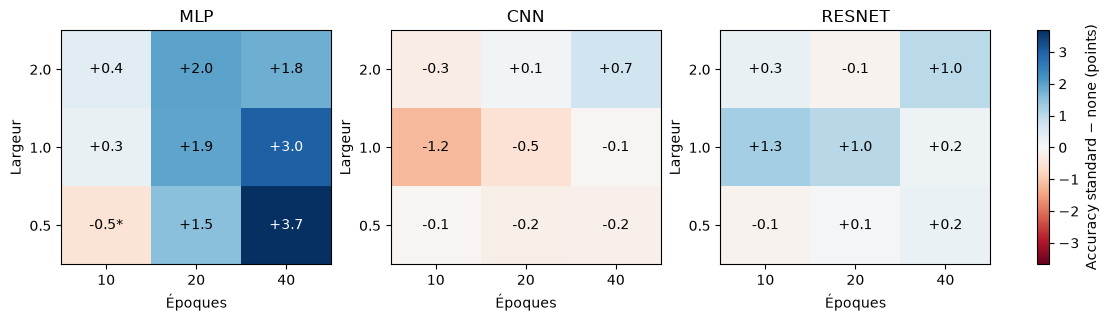

* : intervalle entièrement négatif sur les trois graines exploratoires.


,width_mult,epochs,identified
mlp,0.5,10,True
cnn,1.0,10,False
resnet,2.0,20,False


In [14]:
regimes = {}
if study_config is not None:
    jobs = [(arch, strategy, seed, replace(study_config, width_mult=w, epochs=e), False)
            for arch, w, e, strategy, seed in product(ARCHITECTURES, WIDTH_GRID, EPOCH_GRID,
                                                       ("none", "standard"), SWEEP_SEEDS)]
    sweep = summarize_runs(run_experiments("exploration", jobs))
    if not sweep.empty:
        rows = []
        for (arch, w, e), g in sweep.groupby(["arch", "width", "epochs"]):
            r = summarize_effect(paired_differences(g, "val_acc", "standard", "none"))
            rows.append(dict(arch=arch, method=METHOD[arch], width=w, epochs=e,
                             acc_none=g.loc[g.strategy=="none", "val_acc"].mean(), **r))
        regime_grid = pd.DataFrame(rows)
        regime_grid.to_csv(OUT / "grille_regime.csv", index=False)
        fig, axes = plt.subplots(1, 3, figsize=(11, 3.1), layout="constrained")
        lim = max(0.1, regime_grid.delta.abs().max())
        for ax, arch in zip(axes, ARCHITECTURES):
            g = regime_grid[regime_grid.arch == arch]
            candidates = g[g.ci_high < 0].sort_values(["acc_none","width","epochs"], ascending=[False,True,True])
            best = candidates.iloc[0] if len(candidates) else g.sort_values(["delta","width","epochs"]).iloc[0]
            regimes[arch] = dict(width_mult=float(best.width), epochs=int(best.epochs),
                                 identified=bool(best.ci_high < 0))
            mat = g.pivot(index="width", columns="epochs", values="delta")
            im = ax.imshow(mat, cmap="RdBu", vmin=-lim, vmax=lim, origin="lower", aspect="auto")
            for i, w in enumerate(mat.index):
                for j, e in enumerate(mat.columns):
                    star = "*" if g[(g.width==w) & (g.epochs==e)].ci_high.iloc[0] < 0 else ""
                    ax.text(j, i, f"{mat.loc[w,e]:+.1f}{star}", ha="center", va="center",
                            color="white" if abs(mat.loc[w,e]) > 0.55*lim else "black")
            ax.set(xticks=range(len(mat.columns)), xticklabels=mat.columns, xlabel="Époques",
                   yticks=range(len(mat.index)), yticklabels=mat.index, ylabel="Largeur", title=arch.upper())
        fig.colorbar(im, ax=axes, label="Accuracy standard − none (points)")
        plt.show()
        print("* : intervalle entièrement négatif sur les trois graines exploratoires.")
        display(pd.DataFrame(regimes).T)
else:
    print("La grille sera évaluée après fixation du taux et de la recette d’augmentation.")

### 5.2. Vérifier le régime sur cinq nouvelles graines

La carte précédente détermine où regarder. Pour chaque configuration retenue, nous entraînons les deux témoins, `none` et `standard`, sur cinq graines nouvelles. Ces **30 entraînements** servent à vérifier le régime et, plus loin, à comparer les fenêtres précoces. Les mêmes poids sauvegardés servent aux deux lectures.

Si l’IC de `standard − none` en accuracy de validation est entièrement négatif, le régime est confirmé au sens de notre critère. Si l’intervalle recouvre zéro, le comportement des fenêtres précoces reste intéressant et devra être interprété dans un régime incertain.

In [15]:
control_runs, control_results = [], pd.DataFrame()
confirmation = {}
if len(regimes) == len(ARCHITECTURES):
    jobs = []
    for arch, reg in regimes.items():
        cfg = replace(study_config, width_mult=reg["width_mult"], epochs=reg["epochs"])
        for strategy, seed in product(("none", "standard"), MAIN_SEEDS):
            jobs.append((arch, strategy, seed, cfg, strategy in ("none", PRIMARY)))
    control_runs = run_experiments("validation", jobs, title="Confirmation du régime", index_name="controls")
    control_results = summarize_runs(control_runs)
if not control_results.empty:
    rows = []
    for arch, g in control_results.groupby("arch"):
        r = summarize_effect(paired_differences(g, "val_acc", "standard", "none"))
        confirmation[arch] = r["ci_high"] < 0
        rows.append(dict(model=arch.upper(), mechanism=METHOD[arch], width=g.width.iloc[0],
                         epochs=g.epochs.iloc[0], acc_none=g[g.strategy=="none"].val_acc.mean(),
                         regime="confirmé" if confirmation[arch] else "incertain", **r))
    export_table(pd.DataFrame(rows).drop(columns="p_raw"), "confirmation_regime.csv")
else:
    print("En attente des configurations retenues et de leurs cinq paires de validation.")

Confirmation du régime · mode etude · 30 entraînements prévus


Confirmation du régime:   0%|          | 0/30 [00:00<?, ?run/s]

[1/30] MLP · none · graine 42 · p=0.1 · 10 époques
[2/30] MLP · none · graine 123 · p=0.1 · 10 époques
[3/30] MLP · none · graine 456 · p=0.1 · 10 époques
[4/30] MLP · none · graine 789 · p=0.1 · 10 époques
[5/30] MLP · none · graine 1011 · p=0.1 · 10 époques
[6/30] MLP · standard · graine 42 · p=0.1 · 10 époques
[7/30] MLP · standard · graine 123 · p=0.1 · 10 époques
[8/30] MLP · standard · graine 456 · p=0.1 · 10 époques
[9/30] MLP · standard · graine 789 · p=0.1 · 10 époques
[10/30] MLP · standard · graine 1011 · p=0.1 · 10 époques
[11/30] CNN · none · graine 42 · p=0.1 · 10 époques
[12/30] CNN · none · graine 123 · p=0.1 · 10 époques
[13/30] CNN · none · graine 456 · p=0.1 · 10 époques
[14/30] CNN · none · graine 789 · p=0.1 · 10 époques
[15/30] CNN · none · graine 1011 · p=0.1 · 10 époques
[16/30] CNN · standard · graine 42 · p=0.1 · 10 époques
[17/30] CNN · standard · graine 123 · p=0.1 · 10 époques
[18/30] CNN · standard · graine 456 · p=0.1 · 10 époques
[19/30] CNN · standard ·

  RESNET · none · graine 789:   0%|          | 0/20 [00:00<?, ?ép./s]

  Époque 1/20 · perte train 1.657 · accuracy validation 37.4 %
  Époque 2/20 · perte train 1.371 · accuracy validation 49.6 %
  Époque 3/20 · perte train 1.211 · accuracy validation 55.5 %
  Époque 4/20 · perte train 1.089 · accuracy validation 57.8 %
  Époque 5/20 · perte train 0.994 · accuracy validation 62.1 %
  Époque 6/20 · perte train 0.840 · accuracy validation 67.5 %
  Époque 7/20 · perte train 0.795 · accuracy validation 67.8 %
  Époque 8/20 · perte train 0.745 · accuracy validation 70.6 %
  Époque 9/20 · perte train 0.690 · accuracy validation 70.6 %
  Époque 10/20 · perte train 0.684 · accuracy validation 71.2 %
  Époque 11/20 · perte train 0.604 · accuracy validation 73.1 %
  Époque 12/20 · perte train 0.569 · accuracy validation 75.1 %
  Époque 13/20 · perte train 0.545 · accuracy validation 74.7 %
  Époque 14/20 · perte train 0.538 · accuracy validation 74.9 %
  Époque 15/20 · perte train 0.484 · accuracy validation 76.8 %
  Époque 16/20 · perte train 0.460 · accuracy val

  RESNET · none · graine 1011:   0%|          | 0/20 [00:00<?, ?ép./s]

... (8 outputs left out)

  Époque 1/20 · perte train 1.739 · accuracy validation 33.2 %
  Époque 2/20 · perte train 1.378 · accuracy validation 48.0 %
  Époque 3/20 · perte train 1.213 · accuracy validation 55.5 %
  Époque 4/20 · perte train 1.063 · accuracy validation 58.0 %
  Époque 5/20 · perte train 0.959 · accuracy validation 63.8 %
  Époque 6/20 · perte train 0.832 · accuracy validation 67.8 %
  Époque 7/20 · perte train 0.790 · accuracy validation 68.6 %
  Époque 8/20 · perte train 0.752 · accuracy validation 70.2 %
  Époque 9/20 · perte train 0.670 · accuracy validation 71.3 %
  Époque 10/20 · perte train 0.624 · accuracy validation 73.1 %
  Époque 11/20 · perte train 0.615 · accuracy validation 73.1 %
  Époque 12/20 · perte train 0.549 · accuracy validation 75.9 %
  Époque 13/20 · perte train 0.504 · accuracy validation 76.4 %
  Époque 14/20 · perte train 0.486 · accuracy validation 76.4 %
  Époque 15/20 · perte train 0.478 · accuracy validation 77.2 %
  Époque 16/20 · perte train 0.432 · accuracy val

  RESNET · standard · graine 1011:   0%|          | 0/20 [00:00<?, ?ép./s]

  Époque 1/20 · perte train 1.622 · accuracy validation 38.4 %
  Époque 2/20 · perte train 1.373 · accuracy validation 48.7 %
  Époque 3/20 · perte train 1.262 · accuracy validation 53.8 %
  Époque 4/20 · perte train 1.034 · accuracy validation 61.9 %
  Époque 5/20 · perte train 0.902 · accuracy validation 66.1 %
  Époque 6/20 · perte train 0.867 · accuracy validation 66.8 %
  Époque 7/20 · perte train 0.832 · accuracy validation 67.0 %
  Époque 8/20 · perte train 0.728 · accuracy validation 70.2 %
  Époque 9/20 · perte train 0.686 · accuracy validation 71.5 %
  Époque 10/20 · perte train 0.644 · accuracy validation 73.2 %
  Époque 11/20 · perte train 0.593 · accuracy validation 73.5 %
  Époque 12/20 · perte train 0.583 · accuracy validation 73.6 %
  Époque 13/20 · perte train 0.535 · accuracy validation 75.6 %
  Époque 14/20 · perte train 0.518 · accuracy validation 75.1 %
  Époque 15/20 · perte train 0.477 · accuracy validation 75.9 %
  Époque 16/20 · perte train 0.461 · accuracy val

,model,mechanism,width,epochs,acc_none,regime,n,delta,ci_low,ci_high
0,CNN,Dropout,1.0,10,66.512,incertain,5,-0.504,-1.0230,0.0150
1,MLP,Dropout,0.5,10,53.564,incertain,5,-0.080,-0.4450,0.2850
2,RESNET,Stochastic depth,2.0,20,78.168,incertain,5,-0.028,-0.9031,0.8471


## 6. Expérience principale · comparer les stratégies

Les deux témoins ont servi à caractériser le régime sous la recette retenue. Nous conservons leurs poids et ajoutons, sur les mêmes cinq graines, les quatre fenêtres temporelles. Ces **60 entraînements supplémentaires** complètent les 90 observations de l’expérience principale. Nous lisons d’abord le contraste fixé à 30 %, puis les différences entre durées.

### 6.1. L'early dropout marche-t-il à notre échelle, et sur quels modèles ?

Le régime décrit la réponse au masquage **permanent**. Il reste à tester la prédiction indépendante du papier : couper le masque suffisamment tôt permettrait d’obtenir, à la fin, une perte d’entraînement plus faible que celle du témoin sans masque. Le tableau ci-dessous répond à cette question avec `early_30 − none`. La colonne de validation renseigne ensuite sur la généralisation.

Nous fixons la perte propre à la **dernière époque** comme mesure principale. Une lecture de sensibilité moyenne aussi les cinq dernières époques, une fenêtre qui représente la moitié d’un budget de dix époques et seulement un huitième d’un budget de quarante. Nous rapportons les IC ponctuels et appliquons la correction de **Holm** aux trois tests principaux : elle tient compte du fait que les trois architectures appartiennent à une même famille d’hypothèses. Les comparaisons secondaires restent exploratoires.

Comparaison des fenêtres · mode etude · 60 entraînements prévus


Comparaison des fenêtres:   0%|          | 0/60 [00:00<?, ?run/s]

[1/60] MLP · early_10 · graine 42 · p=0.1 · 10 époques


  MLP · early_10 · graine 42:   0%|          | 0/10 [00:00<?, ?ép./s]

  Époque 1/10 · perte train 1.603 · accuracy validation 41.1 %
  Époque 2/10 · perte train 1.403 · accuracy validation 46.7 %
  Époque 3/10 · perte train 1.298 · accuracy validation 49.6 %
  Époque 4/10 · perte train 1.203 · accuracy validation 51.0 %
  Époque 5/10 · perte train 1.148 · accuracy validation 50.8 %
  Époque 6/10 · perte train 1.078 · accuracy validation 52.1 %
  Époque 7/10 · perte train 1.013 · accuracy validation 52.4 %
  Époque 8/10 · perte train 0.973 · accuracy validation 52.5 %
  Époque 9/10 · perte train 0.956 · accuracy validation 52.9 %
  Époque 10/10 · perte train 0.949 · accuracy validation 53.0 %
[2/60] MLP · early_10 · graine 123 · p=0.1 · 10 époques


  MLP · early_10 · graine 123:   0%|          | 0/10 [00:00<?, ?ép./s]

... (114 outputs left out)

  Époque 1/20 · perte train 1.657 · accuracy validation 37.4 %
  Époque 2/20 · perte train 1.371 · accuracy validation 49.6 %
  Époque 3/20 · perte train 1.211 · accuracy validation 55.5 %
  Époque 4/20 · perte train 1.089 · accuracy validation 57.8 %
  Époque 5/20 · perte train 0.994 · accuracy validation 62.1 %
  Époque 6/20 · perte train 0.840 · accuracy validation 67.5 %
  Époque 7/20 · perte train 0.795 · accuracy validation 67.8 %
  Époque 8/20 · perte train 0.745 · accuracy validation 70.6 %
  Époque 9/20 · perte train 0.690 · accuracy validation 70.6 %
  Époque 10/20 · perte train 0.684 · accuracy validation 71.2 %
  Époque 11/20 · perte train 0.604 · accuracy validation 73.1 %
  Époque 12/20 · perte train 0.569 · accuracy validation 75.1 %
  Époque 13/20 · perte train 0.545 · accuracy validation 74.7 %
  Époque 14/20 · perte train 0.538 · accuracy validation 74.9 %
  Époque 15/20 · perte train 0.514 · accuracy validation 76.3 %
  Époque 16/20 · perte train 0.487 · accuracy val

  RESNET · late_30 · graine 1011:   0%|          | 0/20 [00:00<?, ?ép./s]

  Époque 1/20 · perte train 1.626 · accuracy validation 38.3 %
  Époque 2/20 · perte train 1.397 · accuracy validation 48.2 %
  Époque 3/20 · perte train 1.272 · accuracy validation 52.7 %
  Époque 4/20 · perte train 1.076 · accuracy validation 60.4 %
  Époque 5/20 · perte train 0.908 · accuracy validation 66.2 %
  Époque 6/20 · perte train 0.834 · accuracy validation 67.7 %
  Époque 7/20 · perte train 0.822 · accuracy validation 68.5 %
  Époque 8/20 · perte train 0.720 · accuracy validation 70.8 %
  Époque 9/20 · perte train 0.685 · accuracy validation 71.8 %
  Époque 10/20 · perte train 0.659 · accuracy validation 72.7 %
  Époque 11/20 · perte train 0.590 · accuracy validation 73.9 %
  Époque 12/20 · perte train 0.559 · accuracy validation 75.1 %
  Époque 13/20 · perte train 0.543 · accuracy validation 75.5 %
  Époque 14/20 · perte train 0.481 · accuracy validation 77.0 %
  Époque 15/20 · perte train 0.490 · accuracy validation 76.7 %
  Époque 16/20 · perte train 0.487 · accuracy val

,arch,mechanism,regime,metric,interval_result,n,delta,ci_low,ci_high,p_raw,p_holm_3
0,cnn,Dropout,False,train_loss,sens incertain,5,0.0002,-0.0063,0.0067,0.9309,0.9309
1,cnn,Dropout,False,val_acc,sens incertain,5,-0.1840,-0.8089,0.4409,0.4595,NaN
2,cnn,Dropout,False,train_loss_5,sens incertain,5,-0.0002,-0.0071,0.0067,0.9499,NaN
3,mlp,Dropout,False,train_loss,défavorable,5,0.0312,0.0211,0.0413,0.0010,0.0030
4,mlp,Dropout,False,val_acc,sens incertain,5,0.0480,-0.7135,0.8095,0.8696,NaN
5,mlp,Dropout,False,train_loss_5,défavorable,5,0.0310,0.0210,0.0410,0.0010,NaN
6,resnet,Stochastic depth,False,train_loss,favorable,5,-0.0658,-0.1024,-0.0292,0.0075,0.0150
7,resnet,Stochastic depth,False,val_acc,sens incertain,5,0.7720,-0.0549,1.5989,0.0606,NaN
8,resnet,Stochastic depth,False,train_loss_5,favorable,5,-0.0659,-0.1020,-0.0297,0.0072,NaN


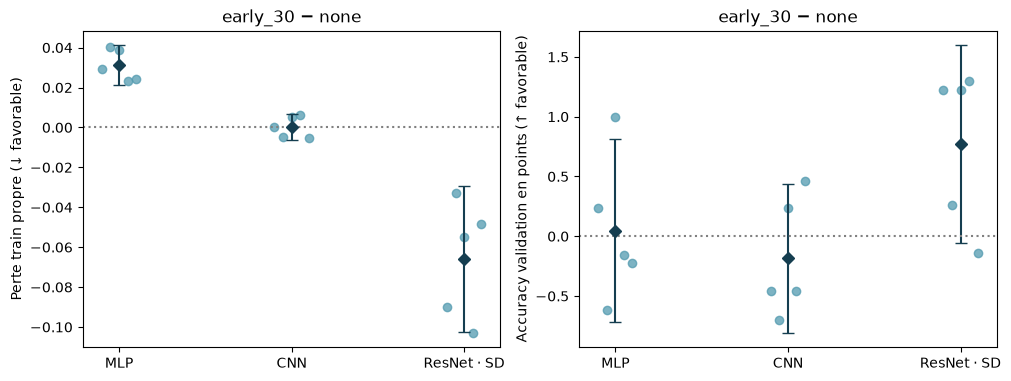

In [16]:
runs, main_results = [], pd.DataFrame()
if control_runs:
    jobs = []
    for arch, reg in regimes.items():
        cfg = replace(study_config, width_mult=reg["width_mult"], epochs=reg["epochs"])
        for strategy, seed in product([*EARLY, LATE], MAIN_SEEDS):
            jobs.append((arch, strategy, seed, cfg, strategy == PRIMARY))
    window_runs = run_experiments("validation", jobs, title="Comparaison des fenêtres", index_name="windows")
    if window_runs:
        runs = control_runs + window_runs
        # L’expérience principale rassemble les témoins et les fenêtres sur les cinq mêmes graines.
        write_run_index(runs, OUT / "validation" / "index_main.csv")
        main_results = summarize_runs(runs)

def holm(pvalues):
    """Ajustement séquentiel des p-values triées, puis retour à l'ordre initial."""
    p = np.asarray(pvalues)
    order = np.argsort(p)
    adjusted = np.empty_like(p, dtype=float)
    adjusted[order] = np.minimum(1, np.maximum.accumulate(p[order] * np.arange(len(p), 0, -1)))
    return adjusted

q1 = pd.DataFrame()
if not main_results.empty:
    rows = []
    for arch, g in main_results.groupby("arch"):
        for metric in ("train_loss", "val_acc", "train_loss_5"):
            r = summarize_effect(paired_differences(g, metric, PRIMARY, "none"))
            rows.append(dict(arch=arch, mechanism=METHOD[arch], regime=confirmation[arch], metric=metric,
                             interval_result=interpret_interval(r, 1 if metric=="val_acc" else -1), **r))
    q1 = pd.DataFrame(rows)
    main_idx = q1.metric == "train_loss"
    q1.loc[main_idx, "p_holm_3"] = holm(q1.loc[main_idx, "p_raw"])
    export_table(q1, "q1_early30.csv")

    # Les points sont les 5 différences indépendantes entre paires de runs.
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.7), layout="constrained")
    for ax, metric, label in zip(axes, ("train_loss", "val_acc"),
                                 ("Perte train propre (↓ favorable)", "Accuracy validation en points (↑ favorable)")):
        for j, arch in enumerate(ARCHITECTURES):
            g = main_results[main_results.arch==arch]
            d = paired_differences(g, metric, PRIMARY, "none")
            r = summarize_effect(d)
            ax.scatter(j + np.linspace(-0.10, 0.10, len(d)), d, color="#529aaf", alpha=.75)
            ax.errorbar(j, r["delta"], yerr=r["ci_high"]-r["delta"], fmt="D", color="#153e50", capsize=4)
        ax.axhline(0, ls=":", color="gray")
        ax.set(xticks=range(3), xticklabels=["MLP","CNN","ResNet · SD"], ylabel=label, title="early_30 − none")
    plt.show()

**Lire les trajectoires.** Une différence finale peut masquer une perte temporairement élevée pendant la phase de masquage puis une récupération après la coupure. Les courbes suivantes moyennent les cinq trajectoires de chaque condition. La ligne verticale marque la dernière époque active de `early_30`. La dispersion entre graines se lit sur la figure des différences appariées ci-dessus.

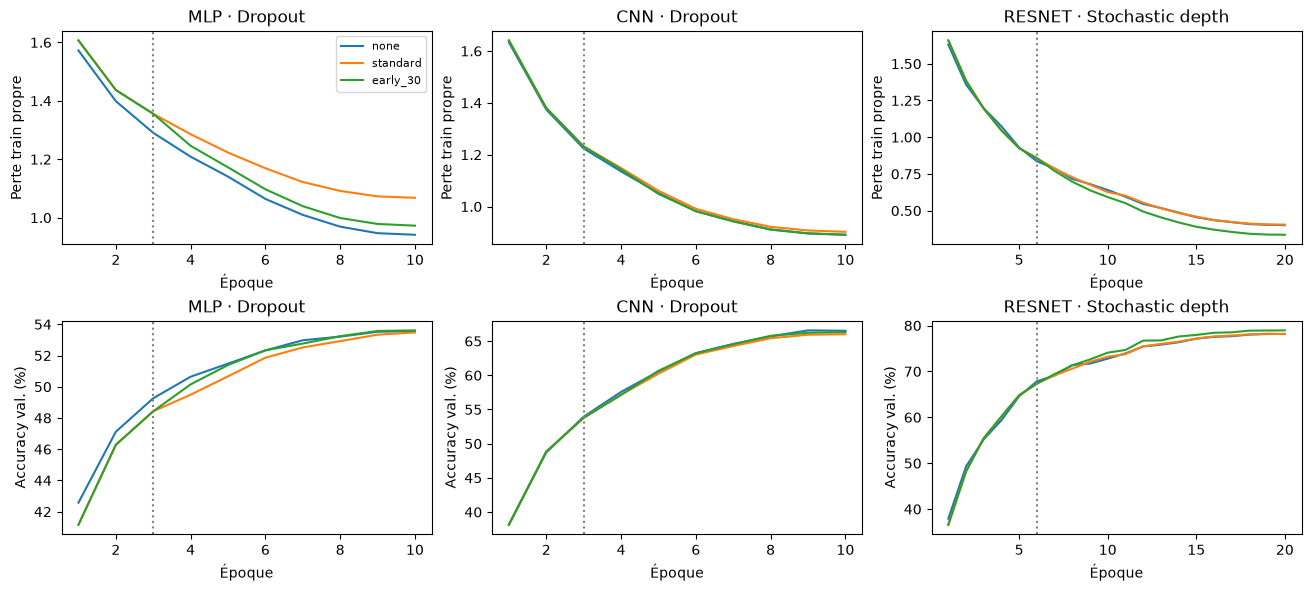

In [17]:
if runs:
    frames = []
    for run in runs:
        ident = run["identite"]
        frames.append(pd.DataFrame(run["history"]).assign(arch=ident["arch"], seed=ident["seed"],
                                                          strategy=ident["strategy"]))
    training_history = pd.concat(frames, ignore_index=True)
    fig, axes = plt.subplots(2, 3, figsize=(13, 5.8), layout="constrained", squeeze=False)
    for j, arch in enumerate(ARCHITECTURES):
        g = training_history[training_history.arch==arch]
        for i, metric in enumerate(("train_loss", "val_acc")):
            ax = axes[i, j]
            for s in ("none", "standard", PRIMARY):
                curve = g[g.strategy==s].groupby("epoch")[metric].mean()
                ax.plot(curve.index, curve, label=s)
            ax.axvline(n_active_epochs(PRIMARY, regimes[arch]["epochs"]), color="gray", ls=":")
            ax.set(title=f"{arch.upper()} · {METHOD[arch]}", xlabel="Époque",
                   ylabel=("Perte train propre", "Accuracy val. (%)")[i])
    axes[0,0].legend(fontsize=8)
    plt.show()

### 6.2. Existe-t-il une durée de dropout optimale selon le type de modèle ?

**Que veut dire « early » : les 10 % premières époques ? 30 % ? 50 % ?** Pour chaque configuration, nous comparons directement les durées entre elles avec les mêmes cinq graines. Nous indiquons aussi le nombre absolu d’époques et de mises à jour actives. Deux fenêtres de 30 % peuvent correspondre à des temps d’optimisation très différents.

Le témoin `none` donne l’origine du graphique. Le classement par accuracy moyenne de validation décrit la grille observée. L’incertitude se lit sur les différences appariées **entre** durées. La grille discrète, le faible nombre de graines et le choix d’un budget par architecture bornent l’interprétation du mot « optimale ».

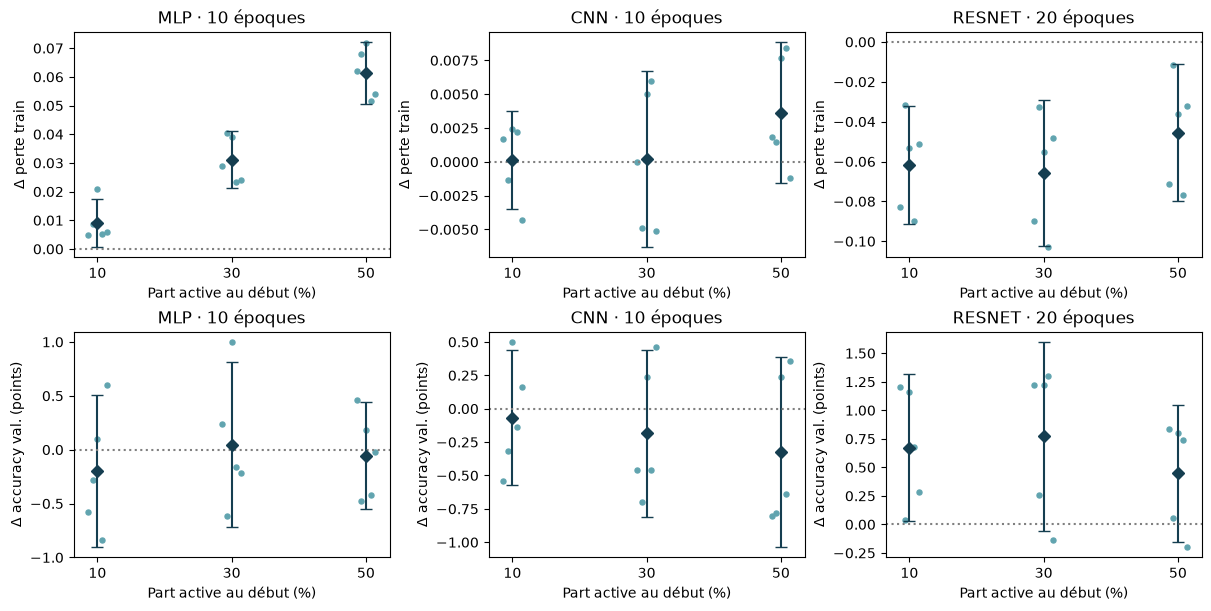

,arch,mechanism,window,active_epochs,active_updates,accuracy_val,delta_train_loss,delta_val_acc
0,mlp,Dropout,early_10,1,352,53.364,0.0091,-0.200
1,mlp,Dropout,early_30,3,1056,53.612,0.0312,0.048
2,mlp,Dropout,early_50,5,1760,53.508,0.0614,-0.056
3,cnn,Dropout,early_10,1,352,66.444,0.0001,-0.068
4,cnn,Dropout,early_30,3,1056,66.328,0.0002,-0.184
5,cnn,Dropout,early_50,5,1760,66.188,0.0036,-0.324
6,resnet,Stochastic depth,early_10,2,704,78.840,-0.0617,0.672
7,resnet,Stochastic depth,early_30,6,2112,78.940,-0.0658,0.772
8,resnet,Stochastic depth,early_50,10,3520,78.616,-0.0455,0.448


,arch,mechanism,comparison,n,delta,ci_low,ci_high
0,mlp,Dropout,early_30 − early_10,5,0.248,-0.719,1.215
2,mlp,Dropout,early_50 − early_10,5,0.144,-0.638,0.926
4,mlp,Dropout,early_50 − early_30,5,-0.104,-0.657,0.449
6,mlp,Dropout,early_30 − late_30,5,-0.032,-0.861,0.797
8,cnn,Dropout,early_30 − early_10,5,-0.116,-0.480,0.248
10,cnn,Dropout,early_50 − early_10,5,-0.256,-0.601,0.089
12,cnn,Dropout,early_50 − early_30,5,-0.140,-0.300,0.020
14,cnn,Dropout,early_30 − late_30,5,-0.068,-0.680,0.544
16,resnet,Stochastic depth,early_30 − early_10,5,0.100,-0.366,0.566
18,resnet,Stochastic depth,early_50 − early_10,5,-0.224,-0.530,0.082


In [18]:
duration_results = pd.DataFrame()
if not main_results.empty:
    rows, contrasts = [], []
    fig, axes = plt.subplots(2, 3, figsize=(12, 6), layout="constrained")
    for j, arch in enumerate(ARCHITECTURES):
        g = main_results[main_results.arch==arch]
        total = regimes[arch]["epochs"]
        steps = math.ceil((BASE.train_subset or (50000-BASE.val_size)) / BASE.batch_size)
        for s in EARLY:
            k = n_active_epochs(s, total)
            row = dict(arch=arch, mechanism=METHOD[arch], window=s, active_epochs=k,
                       active_updates=k*steps, accuracy_val=g[g.strategy==s].val_acc.mean())
            for i, metric in enumerate(("train_loss","val_acc")):
                d = paired_differences(g, metric, s, "none")
                r = summarize_effect(d)
                x = 100*k/total
                axes[i,j].scatter(x + np.linspace(-1.4,1.4,len(d)), d, s=13, color="#61a4af")
                axes[i,j].errorbar(x, r["delta"], yerr=r["ci_high"]-r["delta"], fmt="D", color="#153e50", capsize=4)
                row["delta_"+metric] = r["delta"]
            rows.append(row)
        for i, label in enumerate(("Δ perte train", "Δ accuracy val. (points)")):
            axes[i,j].axhline(0, color="gray", ls=":")
            axes[i,j].set(title=f"{arch.upper()} · {total} époques", ylabel=label,
                          xlabel="Part active au début (%)", xticks=[10,30,50])
        for a, b in [*[(long, short) for short, long in combinations(EARLY, 2)], (PRIMARY, LATE)]:
            for metric in ("val_acc", "train_loss"):
                contrasts.append(dict(arch=arch, mechanism=METHOD[arch], comparison=f"{a} − {b}",
                                      metric=metric, **summarize_effect(paired_differences(g, metric, a, b))))
    plt.show()
    duration_results = pd.DataFrame(rows)
    export_table(duration_results, "q2_durees.csv")
    timing = pd.DataFrame(contrasts)
    timing.to_csv(OUT / "q2_contrastes_directs.csv", index=False)
    display(timing[timing.metric=="val_acc"].drop(columns=["p_raw","metric"]).round(3))

**Contrôle début–fin.** Dans la dernière comparaison, `early_30` et `late_30` ont le même taux et la même durée. Une différence renseigne sur le placement de la fenêtre dans **ce** calendrier d’apprentissage. Une fenêtre précoce laisse davantage d’époques de récupération et coïncide avec des taux d’apprentissage plus élevés. Ces deux propriétés accompagnent le changement de moment.

## 7. Le mécanisme proposé laisse-t-il une trace dans les gradients ?

Une baisse de perte décrit un résultat. Les auteurs proposent une explication plus précise : pendant le début de l’entraînement, les gradients de mini-lots pointeraient dans des directions plus proches les unes des autres et de celle du gradient global. Nous examinons cette prédiction pour `none` et `early_30`.

| Mesure | Calcul sur un checkpoint | Lecture |
|---|---|---|
| GDV · variance des directions | Moyenne de la distance cosinus normalisée ½(1 − cos) entre gradients de mini-lots distincts | Une valeur plus faible indique des directions plus cohérentes entre lots. |
| GDE · erreur de direction | Même distance entre chaque gradient de mini-lot et un gradient de référence sans masque | Une valeur plus faible indique un meilleur alignement avec la référence. |
| Norme du gradient | Longueur euclidienne du gradient, moyennée sur les mini-lots | Elle mesure l’intensité de la dérivée. AdamW transforme cette information avant la mise à jour. |
| Distance à l’initialisation | Distance euclidienne entre poids actuels et poids initiaux | Elle décrit le déplacement net du modèle depuis le départ. |

Une **sonde** est ici une mesure sans mise à jour des poids. Pour l’étude complète, 32 mini-lots propres de 128 images sont comparés à une référence de 4 096 autres images propres. La référence diffère du gradient sur les 45 000 images et de l’objectif avec mixup. Sur un même modèle, nous pouvons allumer puis éteindre les masques sans changer les poids. Les tirages de diagnostic sont isolés de l’aléa de l’apprentissage.

Trois contrastes aident à lire le mécanisme. **Direct** compare sur le checkpoint `none` la sonde masquée et la sonde complète. **Trajectoire** compare les deux entraînements avec leurs masques éteints. **Combiné** compare `early_30` sondé avec masque à `none` sondé sans masque. Après la coupure, le contraste combiné réactive artificiellement les masques. Pour examiner la prédiction précoce, nous limitons la figure aux checkpoints qui terminent une époque où le masque était actif.

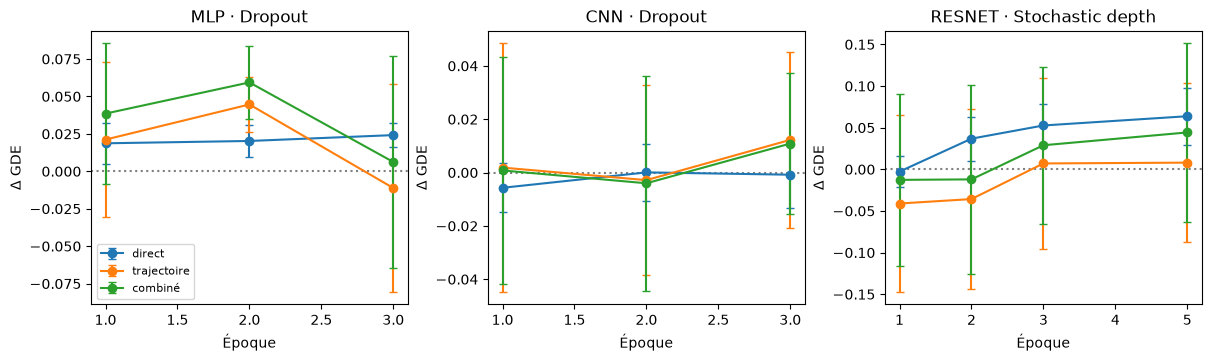

,arch,epoch,metric,delta,ci_low,ci_high
29,cnn,3,gdv,0.0150,-0.0189,0.0489
32,cnn,3,gde,0.0109,-0.0156,0.0374
35,cnn,3,grad_norm,-0.0800,-0.2106,0.0506
83,mlp,3,gdv,0.0010,-0.0548,0.0568
86,mlp,3,gde,0.0062,-0.0648,0.0773
89,mlp,3,grad_norm,-0.2583,-0.3639,-0.1528
146,resnet,5,gdv,0.0401,-0.0745,0.1547
149,resnet,5,gde,0.0443,-0.0630,0.1515
152,resnet,5,grad_norm,-0.4798,-1.2765,0.3168


,arch,n,delta,ci_low,ci_high
0,cnn,5,0.1128,-0.2995,0.5252
1,mlp,5,-0.3317,-0.4699,-0.1935
2,resnet,5,3.3411,2.2991,4.3832


In [19]:
if runs:
    probes = pd.DataFrame([dict(arch=r["identite"]["arch"], seed=r["identite"]["seed"],
                                strategy=r["identite"]["strategy"], **v)
                          for r in runs for v in r["gradients"]])
    probes["condition"] = probes.strategy + "/" + probes["mode"]
    conditions = {"direct": ("none/masked","none/eval"),
                  "trajectoire": (PRIMARY+"/eval","none/eval"),
                  "combiné": (PRIMARY+"/masked","none/eval")}
    rows = []
    for (arch, epoch), g in probes.groupby(["arch","epoch"]):
        for metric, (name, (a,b)) in product(("gdv","gde","grad_norm"), conditions.items()):
            rows.append(dict(arch=arch, epoch=epoch, metric=metric, contrast=name,
                             **summarize_effect(paired_differences(g, metric, a, b, condition="condition"))))
    grad = pd.DataFrame(rows)
    grad.to_csv(OUT / "gradients_contrastes.csv", index=False)
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), layout="constrained")
    for ax, arch in zip(axes, ARCHITECTURES):
        cut = n_active_epochs(PRIMARY, regimes[arch]["epochs"])
        g = grad[(grad.arch==arch) & (grad.metric=="gde") & grad.epoch.between(1, cut)]
        for name in conditions:
            v = g[g.contrast==name].sort_values("epoch")
            ax.errorbar(v.epoch, v.delta, yerr=v.ci_high-v.delta, fmt="o-", capsize=3, label=name)
        ax.axhline(0, color="gray", ls=":")
        ax.set(title=f"{arch.upper()} · {METHOD[arch]}", xlabel="Époque", ylabel="Δ GDE")
    axes[0].legend(fontsize=8)
    plt.show()
    # Dernier checkpoint sondé pendant la fenêtre : comparer aussi GDV et norme.
    active = grad[(grad.epoch > 0) & grad.apply(
        lambda r: r.epoch <= n_active_epochs(PRIMARY, regimes[r.arch]["epochs"]), axis=1)]
    last_probe = active[active.epoch == active.groupby("arch").epoch.transform("max")]
    display(last_probe[last_probe.contrast=="combiné"][["arch","epoch","metric","delta","ci_low","ci_high"]].round(4))
    dist = [dict(arch=arch, **summarize_effect(paired_differences(g, "distance", PRIMARY, "none")))
            for arch, g in main_results.groupby("arch")]
    export_table(pd.DataFrame(dist).drop(columns="p_raw"), "distance_finale.csv")

**Interprétation du mécanisme.** Un contraste combiné négatif pour GDV et GDE pendant la fenêtre va dans le sens de la prédiction directionnelle. Si le contraste direct et celui de trajectoire diffèrent, les poids appris interviennent aussi dans le résultat. L’évolution avec l’époque, le régime de convergence, les données propres et la référence approximative bornent cette lecture. Même accompagnée d’une baisse de perte, une association entre alignement et performance laisse ouverte la direction causale.

## 8. Test, discussion et conclusion

### 8.1. Évaluation sur le test officiel

Les choix de taux et de configuration sont faits sur la validation. Le test évalue une fois les checkpoints finaux du protocole fixé. Nous affichons les scores absolus du témoin et les différences appariées avec `early_30`. Le fichier complet contient toutes les stratégies, ce qui permet de documenter les effets secondaires sans sélectionner une nouvelle durée sur le test.

Le manifeste associe chaque score à l’empreinte des poids correspondants. Une exécution interrompue peut reprendre par checkpoint. La V2 a déjà donné lieu à une lecture du test CIFAR-10 ; la présente étude utilise donc un jeu de test connu de l’équipe.

In [20]:
def evaluate_test_runs(runs):
    folder = OUT / "test"
    rows = []
    Xtest, ytest = None, None
    for run in tqdm(runs, desc="Test officiel", unit="modèle", disable=not (VERBOSE and RUN_TEST)):
        ident = run["identite"]
        checkpoint = Path(run["checkpoint"])
        # Le nom encode le protocole ; l'empreinte vérifie les poids effectivement évalués.
        path = folder / (checkpoint.stem + ".json")
        if not path.exists() and not RUN_TEST:
            return pd.DataFrame()
        sha = hashlib.sha256(checkpoint.read_bytes()).hexdigest()
        if path.exists():
            record = json.loads(path.read_text(encoding="utf8"))
            if record["sha256"] != sha:
                raise ValueError(f"Les poids ont changé depuis le test : {checkpoint.name}")
        else:
            if Xtest is None:
                Xtest, ytest = load_images(train=False)
                if QUICK_MODE:
                    Xtest, ytest = Xtest[:512], ytest[:512]
                Xtest, ytest = Xtest.to(device), ytest.to(device)
            model = build_model(ident["arch"], Config(**ident["cfg"])).to(device)
            model.load_state_dict(torch.load(checkpoint, map_location="cpu", weights_only=True))
            score = evaluate(model, Xtest, ytest)
            record = dict(arch=ident["arch"], method=METHOD[ident["arch"]], strategy=ident["strategy"],
                          seed=ident["seed"], sha256=sha, test_acc=100*score["accuracy"], test_loss=score["loss"])
            folder.mkdir(parents=True, exist_ok=True)
            with tempfile.TemporaryDirectory(dir=folder) as tmp:
                draft = Path(tmp) / "test.json"
                draft.write_text(json.dumps(record), encoding="utf8")
                draft.replace(path)
        if "methode" in record:
            record["method"] = record.pop("methode")
        rows.append(record)
    return pd.DataFrame(rows)

test = evaluate_test_runs(runs) if runs else pd.DataFrame()
if not test.empty:
    test.to_csv(OUT / "test_tous_les_scores.csv", index=False)
    rows = []
    for arch, g in test.groupby("arch"):
        for metric in ("test_acc","test_loss"):
            rows.append(dict(arch=arch, mechanism=METHOD[arch], metric=metric,
                             none=g.loc[g.strategy=="none",metric].mean(),
                             early_30=g.loc[g.strategy==PRIMARY,metric].mean(),
                             **summarize_effect(paired_differences(g,metric,PRIMARY,"none"))))
    export_table(pd.DataFrame(rows).drop(columns="p_raw"), "test_contraste_principal.csv")
else:
    print("Test en attente. Après fixation des choix, activer RUN_TEST puis exécuter la cellule.")

Test officiel:   0%|          | 0/90 [00:00<?, ?modèle/s]

,arch,mechanism,metric,none,early_30,n,delta,ci_low,ci_high
0,cnn,Dropout,test_acc,66.8020,66.7880,5,-0.0140,-0.2010,0.1730
1,cnn,Dropout,test_loss,0.9399,0.9397,5,-0.0002,-0.0052,0.0047
2,mlp,Dropout,test_acc,53.7960,53.8040,5,0.0080,-0.4287,0.4447
3,mlp,Dropout,test_loss,1.3452,1.3391,5,-0.0060,-0.0114,-0.0007
4,resnet,Stochastic depth,test_acc,77.8780,78.9040,5,1.0260,0.1965,1.8555
5,resnet,Stochastic depth,test_loss,0.6614,0.6464,5,-0.0149,-0.0297,-0.0001
